2026-10-03 13:26:49.413080: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791034009.596083      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791034009.650779      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791034010.113450      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791034010.113504      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791034010.113507      58 computation_placer.cc:177] computation placer alr

Using device: cuda
GPU: Tesla T4

 RUNNING DATASET 1: MNIST (Handwritten Digits)

[Loading MNIST dataset (5,000 samples per class)...]
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> MNIST shape: torch.Size([784, 5000, 10])

[Starting Method 1: Standard tSVD | Rank=30]

[Starting Method 2: Paper Baseline (NTD-1SVD) | Rank=30, tol=0.0001]
  -> Paper Baseline Iter   1 | Fit = 0.6182
  -> Paper Baseline Iter  20 | Fit = 0.7033
  -> Paper Baseline Iter  40 | Fit = 0.7214
  -> Paper Baseline Iter  60 | Fit = 0.7311
  -> Paper Baseline Iter  80 | Fit = 0.7376
  -> Paper Baseline Iter 100 | Fit = 0.7423

[Starting Method 3: Hybrid FISTA + Tracking | Rank=30, alpha=0.2, tol=0.0001]
  -> Hybrid Iter   1 | Fit = 0.6182
  -> Hybrid Iter  20 | Fit = 0.7343
  -> Hybrid Iter  40 | Fit = 0.7604
  -> Hybrid Iter  60 | Fit = 0.7711
  -> Hybrid Iter  80 | Fit = 0.7769
  -> Hybrid Iter 100 | Fit = 0.7806


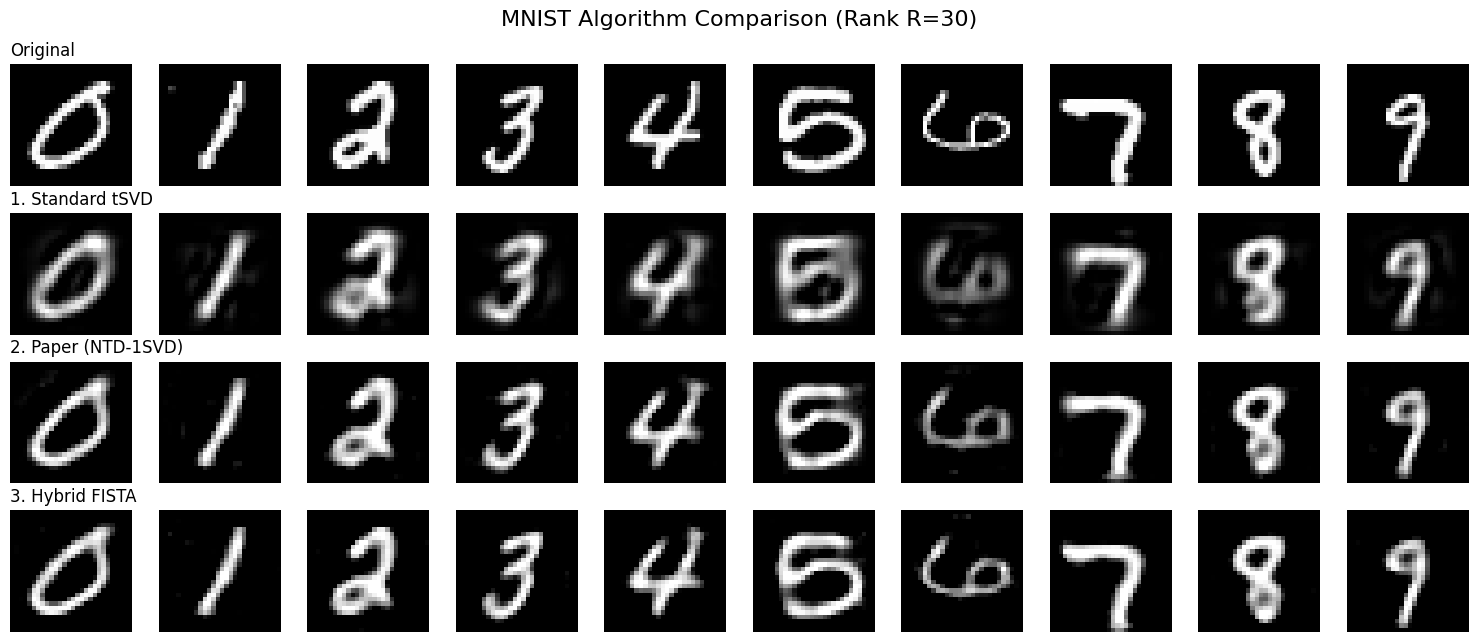


 RUNNING DATASET 2: COIL-20 (Object Poses)

[Loading COIL-20 dataset (Natural Numerical Order)...]
 -> Downloading COIL-20 dataset from Columbia University...
 -> Extracting files...
 -> Processing images into 3D Tensor...
 -> COIL-20 shape: torch.Size([4096, 72, 20])

[Starting Method 1: Standard tSVD | Rank=8]

[Starting Method 2: Paper Baseline (NTD-1SVD) | Rank=8, tol=0.0001]
  -> Paper Baseline Iter   1 | Fit = 0.8127
  -> Paper Baseline Iter  20 | Fit = 0.8286
  -> Paper Baseline Iter  40 | Fit = 0.8319
  -> Converged early at iter 45 (|Δfit| = 0.000098 < tol = 0.0001)

[Starting Method 3: Hybrid FISTA + Tracking | Rank=8, alpha=0.2, tol=0.0001]
  -> Hybrid Iter   1 | Fit = 0.8127
  -> Hybrid Iter  20 | Fit = 0.8339
  -> Hybrid Iter  40 | Fit = 0.8385
  -> Converged early at iter 51 (|Δfit| = 0.000100 < tol = 0.0001)


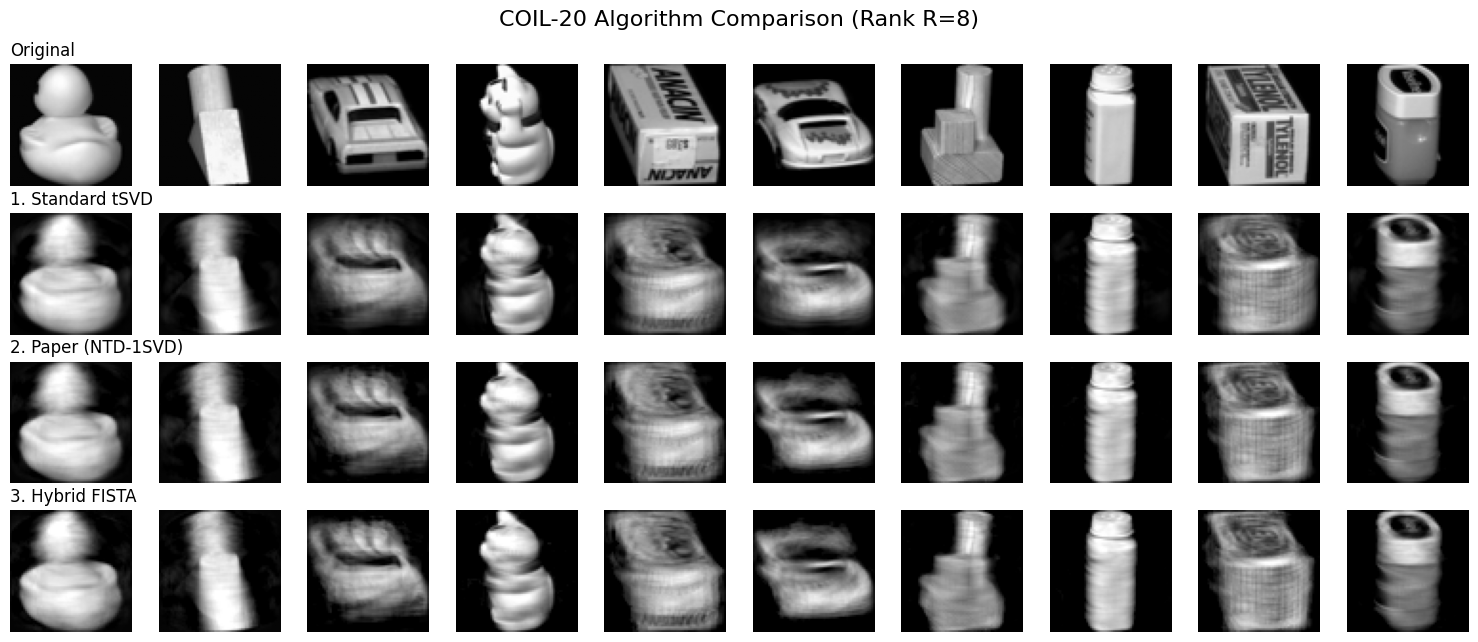


 RUNNING DATASET 3: Enron (Temporal Social Graph)

[Loading Enron dataset from GitLab...]
 -> Download complete via 'master' branch!
 -> Enron shape: torch.Size([105, 105, 28])

[Starting Method 1: Standard tSVD | Rank=15]

[Starting Method 2: Paper Baseline (NTD-1SVD) | Rank=15, tol=0.0001]
  -> Paper Baseline Iter   1 | Fit = 0.6899
  -> Paper Baseline Iter  20 | Fit = 0.8662
  -> Paper Baseline Iter  40 | Fit = 0.9236
  -> Paper Baseline Iter  60 | Fit = 0.9515
  -> Paper Baseline Iter  80 | Fit = 0.9671
  -> Paper Baseline Iter 100 | Fit = 0.9768

[Starting Method 3: Hybrid FISTA + Tracking | Rank=15, alpha=0.2, tol=0.0001]
  -> Hybrid Iter   1 | Fit = 0.6899
  -> Hybrid Iter  20 | Fit = 0.9518
  -> Hybrid Iter  40 | Fit = 0.9968
  -> Converged early at iter 48 (|Δfit| = 0.000086 < tol = 0.0001)

[Generating Figure-Wise Heatmap Comparison...]


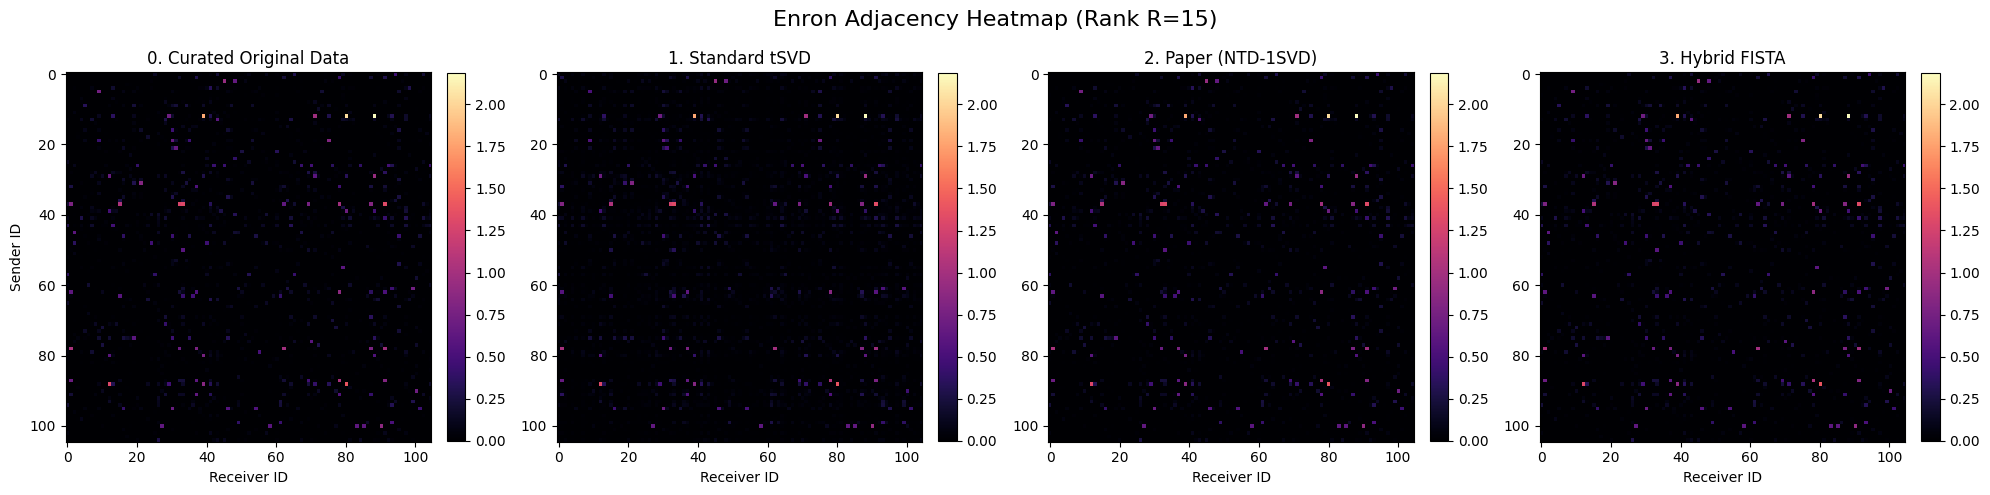


MASTER SUMMARY TABLE: PSNR COMPARISON (dB) ACROSS ALL THREE DATASETS
Dataset         | Rank   | Standard tSVD   | NTD-1SVD (Paper)   | Hybrid FISTA   
--------------------------------------------------------------------------------
MNIST           | R=30  |       17.897 dB |          21.446 dB |       22.922 dB (Δ +1.48 dB)
COIL-20         | R=8   |       21.675 dB |          22.645 dB |       23.040 dB (Δ +0.40 dB)
Enron           | R=15  |       51.055 dB |          73.578 dB |       97.396 dB (Δ +23.82 dB)


In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import math
import matplotlib.pyplot as plt

import torch
import torch.fft
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


# ==========================================
# 1. CORE TENSOR OPERATIONS (GPU)
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)

    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)

    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)

    C = torch.fft.ifft(C_f, dim=2).real
    return C

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        slice_i = A_f[:, :, i]
        U, S, Vh = torch.linalg.svd(slice_i, full_matrices=False)

        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t


# ==========================================
# 2. ALGORITHMS WITH CONVERGENCE CONDITIONS
# ==========================================

# METHOD 1: Standard tSVD
def Standard_tSVD(M, R):
    print(f"\n[Starting Method 1: Standard tSVD | Rank={R}]")
    U, S, V = tsvd(M)
    U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
    X = tprod(tprod(U_r, S_r), tran(V_r))
    return X

# METHOD 2: NTD-1SVD (Paper Baseline with Early Stopping & Best-State Tracking)
def NTD_1SVD_Paper(M, R, maxiters=100, tol=1e-4):
    print(f"\n[Starting Method 2: Paper Baseline (NTD-1SVD) | Rank={R}, tol={tol}]")
    idx0 = (M == 0)
    idx1 = (M > 0)
    X_k = torch.zeros_like(M)
    normM = torch.norm(M)

    fit, fitold, best_fit = 0.0, 0.0, 0.0
    best_X = torch.zeros_like(M)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])

        U, S, V = tsvd(W)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        X_k = tprod(tprod(U_r, S_r), tran(V_r))

        X_pos = torch.clamp(X_k, min=0)
        fit = 1 - (torch.norm(M - X_pos) / normM)

        if fit > best_fit:
            best_fit, best_X = fit.item(), X_k.clone()

        if iter_idx % 20 == 0 or iter_idx == 1:
            print(f"  -> Paper Baseline Iter {iter_idx:3d} | Fit = {fit:.4f}")

        if iter_idx > 1 and abs(fit - fitold) < tol:
            print(f"  -> Converged early at iter {iter_idx} (|Δfit| = {abs(fit - fitold):.6f} < tol = {tol})")
            break

    return best_X

# METHOD 3: Hybrid FISTA + Tracking (With Safety Brake & Early Stopping)
def NTD_tSVD_FISTA_Optimized(X, R, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=1e-4):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    print(f"\n[Starting Method 3: Hybrid FISTA + Tracking | Rank={R}, alpha={alpha}, tol={tol}]")

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Safety Brake logic
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()

        if iter_idx % 20 == 0 or iter_idx == 1:
            print(f"  -> Hybrid Iter {iter_idx:3d} | Fit = {fit:.4f}")

        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            print(f"  -> Converged early at iter {iter_idx} (|Δfit| = {abs(fitold - fit):.6f} < tol = {tol})")
            break

    return best_P


# ==========================================
# 3. UTILITIES & METRICS
# ==========================================
def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: 
        return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()

def plot_four_way_comparison_mnist(original, recon_tsvd, recon_paper, recon_hybrid, sample_idx=420):
    original = original.cpu().numpy()
    recon_tsvd = recon_tsvd.cpu().numpy()
    recon_paper = recon_paper.cpu().numpy()
    recon_hybrid = recon_hybrid.cpu().numpy()

    fig, axes = plt.subplots(4, 10, figsize=(15, 6.5))
    fig.suptitle('MNIST Algorithm Comparison (Rank R=30)', fontsize=16)

    for digit in range(10):
        orig = original[:, sample_idx, digit].reshape(28, 28)
        tsvd_img = recon_tsvd[:, sample_idx, digit].reshape(28, 28)
        paper_img = recon_paper[:, sample_idx, digit].reshape(28, 28)
        hybrid_img = recon_hybrid[:, sample_idx, digit].reshape(28, 28)

        axes[0, digit].imshow(orig, cmap='gray', vmin=0, vmax=1)
        axes[0, digit].axis('off')
        if digit == 0: axes[0, digit].set_title("Original", loc='left')

        axes[1, digit].imshow(tsvd_img, cmap='gray', vmin=0, vmax=1)
        axes[1, digit].axis('off')
        if digit == 0: axes[1, digit].set_title("1. Standard tSVD", loc='left')

        axes[2, digit].imshow(paper_img, cmap='gray', vmin=0, vmax=1)
        axes[2, digit].axis('off')
        if digit == 0: axes[2, digit].set_title("2. Paper (NTD-1SVD)", loc='left')

        axes[3, digit].imshow(hybrid_img, cmap='gray', vmin=0, vmax=1)
        axes[3, digit].axis('off')
        if digit == 0: axes[3, digit].set_title("3. Hybrid FISTA", loc='left')

    plt.tight_layout()
    plt.show()

def plot_four_way_comparison_coil(original, recon_tsvd, recon_paper, recon_hybrid, sample_idx=15, img_size=64):
    original = original.cpu().numpy()
    recon_tsvd = recon_tsvd.cpu().numpy()
    recon_paper = recon_paper.cpu().numpy()
    recon_hybrid = recon_hybrid.cpu().numpy()

    num_cols = 10
    fig, axes = plt.subplots(4, num_cols, figsize=(15, 6.5))
    fig.suptitle('COIL-20 Algorithm Comparison (Rank R=8)', fontsize=16)

    for obj_idx in range(num_cols):
        orig = original[:, sample_idx, obj_idx].reshape(img_size, img_size)
        tsvd_img = recon_tsvd[:, sample_idx, obj_idx].reshape(img_size, img_size)
        paper_img = recon_paper[:, sample_idx, obj_idx].reshape(img_size, img_size)
        hybrid_img = recon_hybrid[:, sample_idx, obj_idx].reshape(img_size, img_size)

        axes[0, obj_idx].imshow(orig, cmap='gray', vmin=0, vmax=1)
        axes[0, obj_idx].axis('off')
        if obj_idx == 0: axes[0, obj_idx].set_title("Original", loc='left')

        axes[1, obj_idx].imshow(tsvd_img, cmap='gray', vmin=0, vmax=1)
        axes[1, obj_idx].axis('off')
        if obj_idx == 0: axes[1, obj_idx].set_title("1. Standard tSVD", loc='left')

        axes[2, obj_idx].imshow(paper_img, cmap='gray', vmin=0, vmax=1)
        axes[2, obj_idx].axis('off')
        if obj_idx == 0: axes[2, obj_idx].set_title("2. Paper (NTD-1SVD)", loc='left')

        axes[3, obj_idx].imshow(hybrid_img, cmap='gray', vmin=0, vmax=1)
        axes[3, obj_idx].axis('off')
        if obj_idx == 0: axes[3, obj_idx].set_title("3. Hybrid FISTA", loc='left')

    plt.tight_layout()
    plt.show()

def plot_network_heatmap(original, m1, m2, m3, rank=15):
    print("\n[Generating Figure-Wise Heatmap Comparison...]")
    orig_adj = torch.sum(original, dim=2).cpu().numpy()
    m1_adj = torch.sum(torch.clamp(m1, min=0), dim=2).cpu().numpy()
    m2_adj = torch.sum(torch.clamp(m2, min=0), dim=2).cpu().numpy()
    m3_adj = torch.sum(torch.clamp(m3, min=0), dim=2).cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f'Enron Adjacency Heatmap (Rank R={rank})', fontsize=16)

    matrices = [orig_adj, m1_adj, m2_adj, m3_adj]
    titles = ["0. Curated Original Data", "1. Standard tSVD", "2. Paper (NTD-1SVD)", "3. Hybrid FISTA"]

    for i in range(4):
        im = axes[i].imshow(np.log1p(matrices[i]), cmap='magma', aspect='auto')
        axes[i].set_title(titles[i])
        axes[i].set_xlabel("Receiver ID")
        if i == 0: axes[i].set_ylabel("Sender ID")
        fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


# ==========================================
# 4. CANONICAL DATA LOADERS
# ==========================================
def load_mnist():
    print("\n[Loading MNIST dataset (5,000 samples per class)...]")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0

    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)

    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(
            imgs[:actual].reshape(actual, 784).T, device=device
        )

    tensor_mnist = tensor_mnist / torch.max(tensor_mnist)
    print(" -> MNIST shape:", tensor_mnist.shape)
    return tensor_mnist

def load_coil20(target_size=(64, 64)):
    print("\n[Loading COIL-20 dataset (Natural Numerical Order)...]")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    extract_dir = "coil-20-proc"

    if not os.path.exists(extract_dir):
        print(" -> Downloading COIL-20 dataset from Columbia University...")
        urllib.request.urlretrieve(url, "coil20.zip")
        print(" -> Extracting files...")
        with zipfile.ZipFile("coil20.zip", 'r') as zip_ref:
            zip_ref.extractall(".")
        if os.path.exists("coil20.zip"):
            os.remove("coil20.zip")

    num_pixels = target_size[0] * target_size[1]
    num_poses = 72
    num_objects = 20

    tensor_coil = torch.zeros((num_pixels, num_poses, num_objects), device=device)

    print(" -> Processing images into 3D Tensor...")
    for obj_idx in range(1, num_objects + 1):
        for pose_idx in range(num_poses):
            filename = os.path.join(extract_dir, f"obj{obj_idx}__{pose_idx}.png")
            if os.path.exists(filename):
                img = Image.open(filename).convert('L').resize(target_size)
                img_arr = np.array(img, dtype=np.float32) / 255.0
                tensor_coil[:, pose_idx, obj_idx - 1] = torch.tensor(img_arr.flatten(), device=device)

    tensor_coil = tensor_coil / torch.max(tensor_coil)
    print(" -> COIL-20 shape:", tensor_coil.shape)
    return tensor_coil, target_size[0]

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    print("\n[Loading Enron dataset from GitLab...]")
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36')]
        urllib.request.install_opener(opener)

        try:
            urllib.request.urlretrieve(url_master, filepath)
            print(" -> Download complete via 'master' branch!")
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)
            print(" -> Download complete via 'main' branch!")

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Failed to download or locate {filepath}")

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d:
                return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d:
                return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3:
                return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None:
                        return res
        elif isinstance(d, np.ndarray):
            if d.dtype.names is not None:
                for name in d.dtype.names:
                    res = find_tensor(d[name])
                    if res is not None: return res
            elif d.ndim >= 3:
                return ('dense', d)
        return None

    result = find_tensor(mat)
    if result is None:
        raise ValueError("Tensor 'subs' and 'vals' missing.")

    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1:
            subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        _, data = result
        T = torch.tensor(data, dtype=torch.float32, device=device)

    T /= torch.max(T)
    print(" -> Enron shape:", T.shape)
    return T


# ==========================================
# 5. UNIFIED EXECUTION PIPELINE
# ==========================================
if __name__ == "__main__":
    CONVERGENCE_TOL = 1e-4

    summary_results = {}

    # -------------------------------------------------------------------------
    # DATASET 1: MNIST (Target Rank = 30)
    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print(" RUNNING DATASET 1: MNIST (Handwritten Digits)")
    print("=" * 70)
    
    tensor_mnist = load_mnist()
    TARGET_RANK_MNIST = 30

    P_tsvd_m = Standard_tSVD(tensor_mnist, R=TARGET_RANK_MNIST)
    final_tsvd_m = torch.clamp(P_tsvd_m, 0, 1)
    psnr_tsvd_m = calculate_psnr(tensor_mnist, final_tsvd_m)

    P_paper_m = NTD_1SVD_Paper(tensor_mnist, R=TARGET_RANK_MNIST, maxiters=100, tol=CONVERGENCE_TOL)
    final_paper_m = torch.clamp(P_paper_m, 0, 1)
    psnr_paper_m = calculate_psnr(tensor_mnist, final_paper_m)

    P_hybrid_m = NTD_tSVD_FISTA_Optimized(
        tensor_mnist, R=TARGET_RANK_MNIST, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=CONVERGENCE_TOL
    )
    final_hybrid_m = torch.clamp(P_hybrid_m, 0, 1)
    psnr_hybrid_m = calculate_psnr(tensor_mnist, final_hybrid_m)

    summary_results["MNIST"] = {
        "rank": TARGET_RANK_MNIST,
        "tsvd": psnr_tsvd_m,
        "paper": psnr_paper_m,
        "hybrid": psnr_hybrid_m
    }

    plot_four_way_comparison_mnist(tensor_mnist, final_tsvd_m, final_paper_m, final_hybrid_m, sample_idx=420)

    del tensor_mnist, P_tsvd_m, P_paper_m, P_hybrid_m, final_tsvd_m, final_paper_m, final_hybrid_m
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # -------------------------------------------------------------------------
    # DATASET 2: COIL-20 (Target Rank = 8)
    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print(" RUNNING DATASET 2: COIL-20 (Object Poses)")
    print("=" * 70)
    
    tensor_coil, img_dim = load_coil20(target_size=(64, 64))
    TARGET_RANK_COIL = 8

    P_tsvd_c = Standard_tSVD(tensor_coil, R=TARGET_RANK_COIL)
    final_tsvd_c = torch.clamp(P_tsvd_c, 0, 1)
    psnr_tsvd_c = calculate_psnr(tensor_coil, final_tsvd_c)

    P_paper_c = NTD_1SVD_Paper(tensor_coil, R=TARGET_RANK_COIL, maxiters=100, tol=CONVERGENCE_TOL)
    final_paper_c = torch.clamp(P_paper_c, 0, 1)
    psnr_paper_c = calculate_psnr(tensor_coil, final_paper_c)

    P_hybrid_c = NTD_tSVD_FISTA_Optimized(
        tensor_coil, R=TARGET_RANK_COIL, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=CONVERGENCE_TOL
    )
    final_hybrid_c = torch.clamp(P_hybrid_c, 0, 1)
    psnr_hybrid_c = calculate_psnr(tensor_coil, final_hybrid_c)

    summary_results["COIL-20"] = {
        "rank": TARGET_RANK_COIL,
        "tsvd": psnr_tsvd_c,
        "paper": psnr_paper_c,
        "hybrid": psnr_hybrid_c
    }

    plot_four_way_comparison_coil(tensor_coil, final_tsvd_c, final_paper_c, final_hybrid_c, sample_idx=15, img_size=img_dim)

    del tensor_coil, P_tsvd_c, P_paper_c, P_hybrid_c, final_tsvd_c, final_paper_c, final_hybrid_c
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # -------------------------------------------------------------------------
    # DATASET 3: Enron (Target Rank = 15)
    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print(" RUNNING DATASET 3: Enron (Temporal Social Graph)")
    print("=" * 70)
    
    tensor_enron = load_gitlab_enron_mat()
    TARGET_RANK_ENRON = 15

    P_tsvd_e = Standard_tSVD(tensor_enron, R=TARGET_RANK_ENRON)
    final_tsvd_e = torch.clamp(P_tsvd_e, 0, 1)
    psnr_tsvd_e = calculate_psnr(tensor_enron, final_tsvd_e)

    P_paper_e = NTD_1SVD_Paper(tensor_enron, R=TARGET_RANK_ENRON, maxiters=100, tol=CONVERGENCE_TOL)
    final_paper_e = torch.clamp(P_paper_e, 0, 1)
    psnr_paper_e = calculate_psnr(tensor_enron, final_paper_e)

    P_hybrid_e = NTD_tSVD_FISTA_Optimized(
        tensor_enron, R=TARGET_RANK_ENRON, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=CONVERGENCE_TOL
    )
    final_hybrid_e = torch.clamp(P_hybrid_e, 0, 1)
    psnr_hybrid_e = calculate_psnr(tensor_enron, final_hybrid_e)

    summary_results["Enron"] = {
        "rank": TARGET_RANK_ENRON,
        "tsvd": psnr_tsvd_e,
        "paper": psnr_paper_e,
        "hybrid": psnr_hybrid_e
    }

    plot_network_heatmap(tensor_enron, final_tsvd_e, final_paper_e, final_hybrid_e, TARGET_RANK_ENRON)

    del tensor_enron, P_tsvd_e, P_paper_e, P_hybrid_e, final_tsvd_e, final_paper_e, final_hybrid_e
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # -------------------------------------------------------------------------
    # FINAL RECONSTRUCTION & COMPRESSION BENCHMARK SUMMARY
    # -------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("MASTER SUMMARY TABLE: PSNR COMPARISON (dB) ACROSS ALL THREE DATASETS")
    print("=" * 80)
    print(f"{'Dataset':<15} | {'Rank':<6} | {'Standard tSVD':<15} | {'NTD-1SVD (Paper)':<18} | {'Hybrid FISTA':<15}")
    print("-" * 80)
    for ds, res in summary_results.items():
        delta = res['hybrid'] - res['paper']
        print(f"{ds:<15} | R={res['rank']:<3} | {res['tsvd']:>12.3f} dB | {res['paper']:>15.3f} dB | {res['hybrid']:>12.3f} dB (Δ +{delta:.2f} dB)")
    print("=" * 80)

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import math

import torch
import torch.fft
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


# ==========================================
# 1. CORE TENSOR OPERATIONS (GPU)
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)

    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)

    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)

    C = torch.fft.ifft(C_f, dim=2).real
    return C

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        slice_i = A_f[:, :, i]
        U, S, Vh = torch.linalg.svd(slice_i, full_matrices=False)

        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t


# ==========================================
# 2. ABLATION ALGORITHM (DENSITY-ADAPTIVE FISTA)
# ==========================================
def Density_Adaptive_FISTA_Ablation(X, R, alpha=0.15, mu=0.80, maxiters=100, tol=1e-4, use_memory=True):
    mode_str = "WITH" if use_memory else "WITHOUT"
    print(f"\n[Running Density-Adaptive FISTA {mode_str} Memory Tracking | Rank={R}]")
    
    normX = torch.norm(X)
    XX = X.clone()
    idx0 = (XX == 0)
    idx1 = (XX > 0)

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # Decomposition directly on momentum state (Q is 0 if memory is disabled)
        Z = Y + Q
        U, S, V = tsvd(Z)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        # Strict Background Projection
        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Conditional Memory Tracking & Energy Clamp
        if use_memory:
            Q = mu * Q + alpha * (M_new - P)
            norm_Y = torch.norm(Y)
            norm_Q = torch.norm(Q)
            safety_limit = 0.20 * norm_Y
            if norm_Q > safety_limit:
                Q = Q * (safety_limit / norm_Q)

        P_pos = torch.clamp(P, min=0)
        fit = 1.0 - (torch.norm(XX - P_pos) / normX).item()

        # Safety Brake logic
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            fit = fitold
            if use_memory:
                Q = Q * 0.5
        else:
            t_next = (1.0 + math.sqrt(1.0 + 4.0 * t_step**2)) / 2.0
            beta = (t_step - 1.0) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()

        if iter_idx % 20 == 0 or iter_idx == 1:
            print(f"  -> Iter {iter_idx:3d} | Fit = {fit:.4f}")

        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            print(f"  -> Converged early at iter {iter_idx} (|Δfit| = {abs(fitold - fit):.6f} < tol = {tol})")
            break

    return best_P


# ==========================================
# 3. METRIC FUNCTION
# ==========================================
def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: 
        return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()


# ==========================================
# 4. DATA LOADERS
# ==========================================
def load_mnist():
    print("\n[Loading MNIST dataset (5,000 samples per class)...]")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0

    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)

    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(
            imgs[:actual].reshape(actual, 784).T, device=device
        )

    tensor_mnist = tensor_mnist / torch.max(tensor_mnist)
    print(" -> MNIST shape:", tensor_mnist.shape)
    return tensor_mnist

def load_coil20(target_size=(64, 64)):
    print("\n[Loading COIL-20 dataset (Natural Numerical Order)...]")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    extract_dir = "coil-20-proc"

    if not os.path.exists(extract_dir):
        print(" -> Downloading COIL-20 dataset from Columbia University...")
        urllib.request.urlretrieve(url, "coil20.zip")
        print(" -> Extracting files...")
        with zipfile.ZipFile("coil20.zip", 'r') as zip_ref:
            zip_ref.extractall(".")
        if os.path.exists("coil20.zip"):
            os.remove("coil20.zip")

    num_pixels = target_size[0] * target_size[1]
    num_poses = 72
    num_objects = 20

    tensor_coil = torch.zeros((num_pixels, num_poses, num_objects), device=device)

    print(" -> Processing images into 3D Tensor...")
    for obj_idx in range(1, num_objects + 1):
        for pose_idx in range(num_poses):
            filename = os.path.join(extract_dir, f"obj{obj_idx}__{pose_idx}.png")
            if os.path.exists(filename):
                img = Image.open(filename).convert('L').resize(target_size)
                img_arr = np.array(img, dtype=np.float32) / 255.0
                tensor_coil[:, pose_idx, obj_idx - 1] = torch.tensor(img_arr.flatten(), device=device)

    tensor_coil = tensor_coil / torch.max(tensor_coil)
    print(" -> COIL-20 shape:", tensor_coil.shape)
    return tensor_coil

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    print("\n[Loading Enron dataset from GitLab...]")
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)')]
        urllib.request.install_opener(opener)

        try:
            urllib.request.urlretrieve(url_master, filepath)
            print(" -> Download complete via 'master' branch!")
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)
            print(" -> Download complete via 'main' branch!")

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Failed to download or locate {filepath}")

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d:
                return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d:
                return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3:
                return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None:
                        return res
        elif isinstance(d, np.ndarray):
            if d.dtype.names is not None:
                for name in d.dtype.names:
                    res = find_tensor(d[name])
                    if res is not None: return res
            elif d.ndim >= 3:
                return ('dense', d)
        return None

    result = find_tensor(mat)
    if result is None:
        raise ValueError("Tensor 'subs' and 'vals' missing.")

    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1:
            subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        _, data = result
        T = torch.tensor(data, dtype=torch.float32, device=device)

    T /= torch.max(T)
    print(" -> Enron shape:", T.shape)
    return T


# ==========================================
# 5. ABLATION BENCHMARK EXECUTION PIPELINE
# ==========================================
if __name__ == "__main__":
    CONVERGENCE_TOL = 1e-4

    datasets = {
        "MNIST": {"loader": load_mnist, "rank": 30},
        "COIL-20": {"loader": load_coil20, "rank": 8},
        "Enron": {"loader": load_gitlab_enron_mat, "rank": 15}
    }

    ablation_results = {}

    for name, config in datasets.items():
        print("\n" + "=" * 70)
        print(f" ABLATION TEST: {name} (Rank R={config['rank']})")
        print("=" * 70)

        tensor_data = config["loader"]()
        R = config["rank"]

        # 1. Density-Adaptive FISTA WITHOUT Memory Tracking
        P_no_mem = Density_Adaptive_FISTA_Ablation(tensor_data, R=R, maxiters=100, tol=CONVERGENCE_TOL, use_memory=False)
        psnr_no_mem = calculate_psnr(tensor_data, torch.clamp(P_no_mem, min=0, max=1))
        print(f"  [Result] PSNR (w/o Memory) : {psnr_no_mem:.3f} dB")

        # 2. Density-Adaptive FISTA WITH Memory Tracking
        P_with_mem = Density_Adaptive_FISTA_Ablation(tensor_data, R=R, alpha=0.15, mu=0.80, maxiters=100, tol=CONVERGENCE_TOL, use_memory=True)
        psnr_with_mem = calculate_psnr(tensor_data, torch.clamp(P_with_mem, min=0, max=1))
        print(f"  [Result] PSNR (w/ Memory)  : {psnr_with_mem:.3f} dB")

        gain = psnr_with_mem - psnr_no_mem
        print(f"  >>> PSNR Gain due to Memory Tracking: {gain:+.3f} dB")

        ablation_results[name] = {
            "rank": R,
            "psnr_no_mem": psnr_no_mem,
            "psnr_with_mem": psnr_with_mem,
            "gain": gain
        }

        del tensor_data, P_no_mem, P_with_mem
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ==========================================
    # 6. SUMMARY TABLE
    # ==========================================
    print("\n" + "=" * 80)
    print("ABLATION STUDY: MEMORY TRACKING IMPACT ON PSNR (dB)")
    print("=" * 80)
    print(f"{'Dataset':<15} | {'Rank':<6} | {'w/o Memory':<16} | {'w/ Memory':<16} | {'Δ Gain (dB)':<12}")
    print("-" * 80)
    for ds, res in ablation_results.items():
        print(f"{ds:<15} | R={res['rank']:<3} | {res['psnr_no_mem']:>12.3f} dB | {res['psnr_with_mem']:>12.3f} dB | {res['gain']:>+10.3f} dB")
    print("=" * 80)

2026-10-19 22:49:53.759243: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792450193.901343      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792450193.942677      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792450194.294025      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792450194.294069      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792450194.294072      58 computation_placer.cc:177] computation placer alr

Using device: cuda
GPU: Tesla T4

 ABLATION TEST: MNIST (Rank R=30)

[Loading MNIST dataset (5,000 samples per class)...]
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> MNIST shape: torch.Size([784, 5000, 10])

[Running Density-Adaptive FISTA WITHOUT Memory Tracking | Rank=30]
  -> Iter   1 | Fit = 0.6182
  -> Iter  20 | Fit = 0.7367
  -> Iter  40 | Fit = 0.7610
  -> Iter  60 | Fit = 0.7713
  -> Iter  80 | Fit = 0.7770
  -> Iter 100 | Fit = 0.7806
  [Result] PSNR (w/o Memory) : 22.922 dB

[Running Density-Adaptive FISTA WITH Memory Tracking | Rank=30]
  -> Iter   1 | Fit = 0.6182
  -> Iter  20 | Fit = 0.7517
  -> Iter  40 | Fit = 0.7711
  -> Iter  60 | Fit = 0.7784
  -> Iter  80 | Fit = 0.7824
  -> Iter 100 | Fit = 0.7849
  [Result] PSNR (w/ Memory)  : 23.103 dB
  >>> PSNR Gain due to Memory Tracking: +0.181 dB

 ABLATION TEST: COIL-20 (Rank R=8)

[Loading COIL-20 dataset (Natural Numerical Order)...]
 -> Downloading COIL-20 dataset from Columbia University...
 -> Extracting fi

# Density-Adaptive Optimization Framework

In [2]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import math

import torch
import torch.fft
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS (GPU)
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)

    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)

    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)

    C = torch.fft.ifft(C_f, dim=2).real
    return C

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t


# ==========================================
# 2. THE PROPOSED DENSITY-ADAPTIVE ALGORITHM
# ==========================================
def NTD_tSVD_FISTA_Adaptive(
    X, R, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    print(f"\n[Running Proposed Adaptive Hybrid FISTA | Rank={R}]")
    
    # 1. Calculate Tensor Density to determine optimization mode
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) # 5% sparsity threshold

    if use_tracking:
        print(f"  -> Density: {tensor_density*100:.1f}% (>5%). Activating Refined Dual Tracking.")
    else:
        print(f"  -> Density: {tensor_density*100:.1f}% (<5%). Hyper-sparse graph detected. Disabling Tracking.")

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)
    total_iters = maxiters

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # SVD Step
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Apply Dual Tracking ONLY if active
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual

            norm_y = torch.norm(Y)
            norm_q = torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Safety Brake
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking:
                Q, fit = Q * 0.5, fitold
            else:
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()

        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            print(f"  -> Converged at iter {iter_idx} (Fit = {fit:.4f})")
            total_iters = iter_idx
            break

    return best_P, total_iters


# ==========================================
# 3. BASELINES & METRICS
# ==========================================
def NTD_1SVD_Paper(M, R, maxiters=100, tol=1e-4):
    print(f"\n[Running Baseline: NTD-1SVD | Rank={R}]")
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    normM = torch.norm(M)
    fit, fitold, best_fit = 0.0, 0.0, 0.0
    best_X = torch.zeros_like(M)
    total_iters = maxiters

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])

        U, S, V = tsvd(W)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        X_k = tprod(tprod(U_r, S_r), tran(V_r))

        X_pos = torch.clamp(X_k, min=0)
        fit = 1 - (torch.norm(M - X_pos) / normM)

        if fit > best_fit:
            best_fit, best_X = fit.item(), X_k.clone()

        if iter_idx > 1 and abs(fit - fitold) < tol:
            print(f"  -> Converged at iter {iter_idx} (Fit = {fit:.4f})")
            total_iters = iter_idx
            break
            
    return best_X, total_iters

def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()


# ==========================================
# 4. DATA LOADERS (Omitted for brevity)
# ==========================================
# [Insert load_mnist, load_coil20, load_gitlab_enron_mat exactly as they are]


# ==========================================
# 5. BENCHMARK EXECUTION
# ==========================================
if __name__ == "__main__":
    CONVERGENCE_TOL = 1e-4

    datasets = {
        "MNIST": {"loader": load_mnist, "rank": 30},
        "COIL-20": {"loader": load_coil20, "rank": 8},
        "Enron": {"loader": load_gitlab_enron_mat, "rank": 15}
    }

    results = {}

    for name, config in datasets.items():
        print("\n" + "=" * 70)
        print(f" EVALUATING: {name}")
        print("=" * 70)

        tensor_data = config["loader"]()
        R = config["rank"]

        # 1. Baseline
        P_base, iters_base = NTD_1SVD_Paper(tensor_data, R=R, maxiters=100, tol=CONVERGENCE_TOL)
        psnr_base = calculate_psnr(tensor_data, torch.clamp(P_base, 0, 1))

        # 2. Proposed Adaptive Algorithm
        P_prop, iters_prop = NTD_tSVD_FISTA_Adaptive(tensor_data, R=R, maxiters=100, tol=CONVERGENCE_TOL)
        psnr_prop = calculate_psnr(tensor_data, torch.clamp(P_prop, 0, 1))

        results[name] = {
            "rank": R,
            "psnr_base": psnr_base,
            "iters_base": iters_base,
            "psnr_prop": psnr_prop,
            "iters_prop": iters_prop,
            "gain_psnr": psnr_prop - psnr_base,
            "delta_iters": iters_prop - iters_base
        }
        
        del tensor_data, P_base, P_prop
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # SUMMARY TABLE
    print("\n" + "=" * 90)
    print("FINAL BENCHMARK: BASELINE vs. PROPOSED ADAPTIVE ALGORITHM")
    print("=" * 90)
    print(f"{'Dataset':<10} | {'Rank':<5} | {'NTD-1SVD (Baseline)':<24} | {'Proposed Adaptive Method':<26} | {'Δ PSNR':<10} | {'Δ Iters':<8}")
    print("-" * 90)
    for ds, res in results.items():
        b_str = f"{res['psnr_base']:.3f} dB ({res['iters_base']} it)"
        p_str = f"{res['psnr_prop']:.3f} dB ({res['iters_prop']} it)"
        print(f"{ds:<10} | R={res['rank']:<3} | {b_str:<24} | {p_str:<26} | {res['gain_psnr']:>+7.3f} dB | {res['delta_iters']:>+5d} it")
    print("=" * 90)

Using device: cuda

 EVALUATING: MNIST

[Loading MNIST dataset (5,000 samples per class)...]
 -> MNIST shape: torch.Size([784, 5000, 10])

[Running Baseline: NTD-1SVD | Rank=30]

[Running Proposed Adaptive Hybrid FISTA | Rank=30]
  -> Density: 19.3% (>5%). Activating Refined Dual Tracking.

 EVALUATING: COIL-20

[Loading COIL-20 dataset (Natural Numerical Order)...]
 -> Processing images into 3D Tensor...
 -> COIL-20 shape: torch.Size([4096, 72, 20])

[Running Baseline: NTD-1SVD | Rank=8]
  -> Converged at iter 45 (Fit = 0.8324)

[Running Proposed Adaptive Hybrid FISTA | Rank=8]
  -> Density: 62.6% (>5%). Activating Refined Dual Tracking.
  -> Converged at iter 45 (Fit = 0.8411)

 EVALUATING: Enron

[Loading Enron dataset from GitLab...]
 -> Enron shape: torch.Size([105, 105, 28])

[Running Baseline: NTD-1SVD | Rank=15]

[Running Proposed Adaptive Hybrid FISTA | Rank=15]
  -> Density: 2.8% (<5%). Hyper-sparse graph detected. Disabling Tracking.
  -> Converged at iter 47 (Fit = 0.9986)


Number of GPUs available: 2

[Loading MNIST dataset via torchvision...]


100%|██████████| 9.91M/9.91M [00:00<00:00, 37.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.00MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.1MB/s]


Distributing dataset to GPUs...
Dataset shape per GPU: torch.Size([784, 5000, 10])

EVALUATING ALGORITHMS ACROSS RANKS 1 TO 70 (DUAL GPU)


/tmp/ipykernel_58/1121225286.py:39: UserWarning: Attempting to run cuFFT, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/native/cuda/SpectralOps.cpp:256.)
  A_f = torch.fft.fft(A, dim=2)


[Done] Rank  1 | Handled by GPU 1 | Hybrid PSNR: 12.96 dB
[Done] Rank  2 | Handled by GPU 0 | Hybrid PSNR: 13.43 dB
[Done] Rank  4 | Handled by GPU 0 | Hybrid PSNR: 14.10 dB
[Done] Rank  3 | Handled by GPU 1 | Hybrid PSNR: 13.77 dB
[Done] Rank  6 | Handled by GPU 0 | Hybrid PSNR: 14.67 dB
[Done] Rank  5 | Handled by GPU 1 | Hybrid PSNR: 14.38 dB
[Done] Rank  8 | Handled by GPU 0 | Hybrid PSNR: 15.29 dB
[Done] Rank  7 | Handled by GPU 1 | Hybrid PSNR: 14.96 dB
[Done] Rank 10 | Handled by GPU 0 | Hybrid PSNR: 15.93 dB
[Done] Rank  9 | Handled by GPU 1 | Hybrid PSNR: 15.60 dB
[Done] Rank 12 | Handled by GPU 0 | Hybrid PSNR: 16.58 dB
[Done] Rank 11 | Handled by GPU 1 | Hybrid PSNR: 16.24 dB
[Done] Rank 14 | Handled by GPU 0 | Hybrid PSNR: 17.29 dB
[Done] Rank 13 | Handled by GPU 1 | Hybrid PSNR: 16.94 dB
[Done] Rank 16 | Handled by GPU 0 | Hybrid PSNR: 18.04 dB
[Done] Rank 15 | Handled by GPU 1 | Hybrid PSNR: 17.67 dB
[Done] Rank 18 | Handled by GPU 0 | Hybrid PSNR: 18.79 dB
[Done] Rank 17

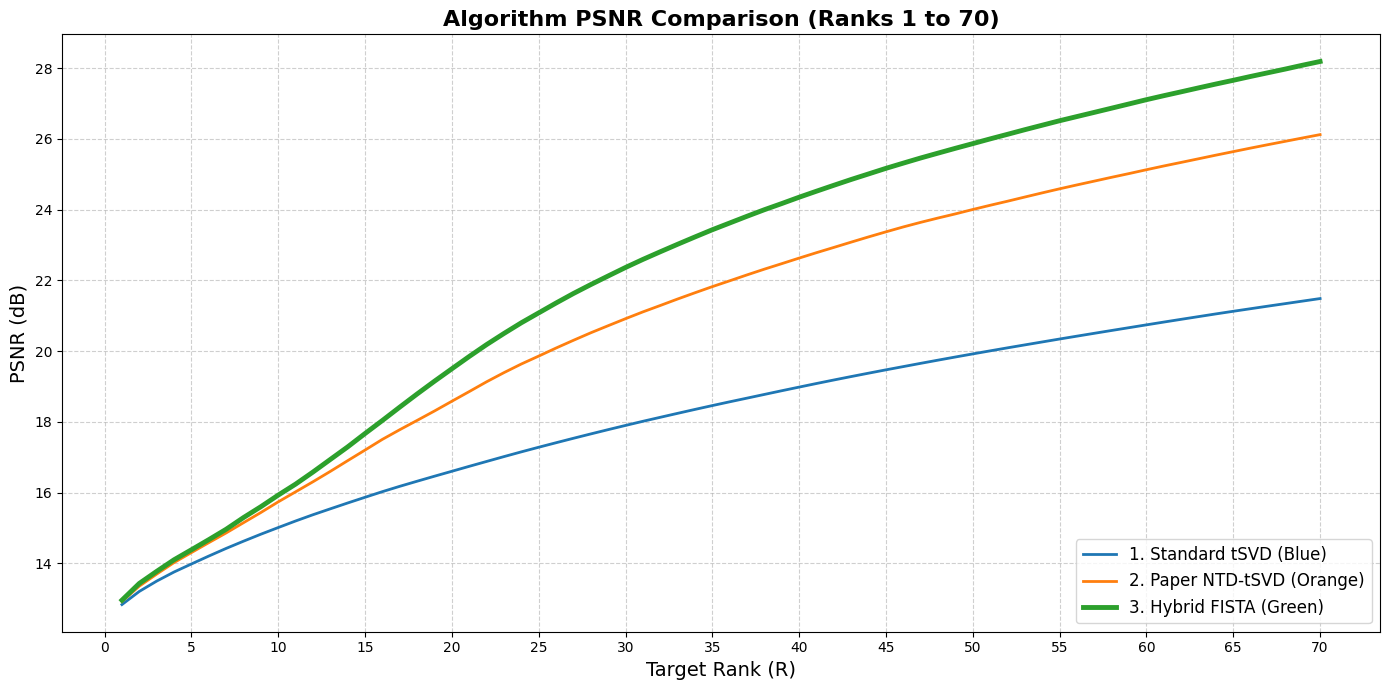

In [2]:
import torch
import torch.fft
import math
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
import concurrent.futures

# Enable TF32 for faster math on T4 GPUs
torch.backends.cuda.matmul.allow_tf32 = True

print(f"Number of GPUs available: {torch.cuda.device_count()}")
if torch.cuda.device_count() < 2:
    print("WARNING: Only 1 GPU detected. Switch Kaggle Accelerator to 'GPU T4x2' for maximum speed.")

# ==========================================
# 1. TENSOR OPERATIONS (GPU-Agnostic)
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)

    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)

    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)

    C = torch.fft.ifft(C_f, dim=2).real
    return C

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)
    
    # Detect which GPU this specific tensor is sitting on
    curr_dev = A.device 

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=curr_dev)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=curr_dev)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=curr_dev)

    for i in range(n3):
        slice_i = A_f[:, :, i]
        U, S, Vh = torch.linalg.svd(slice_i, full_matrices=False)

        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t

# ==========================================
# 2. ALGORITHMS
# ==========================================

# METHOD 1: Standard tSVD
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    U_r = U[:, :R, :]
    S_r = S[:R, :R, :]
    V_r = V[:, :R, :]
    X = tprod(tprod(U_r, S_r), tran(V_r))
    return X

# METHOD 2: NTD-1SVD (The Paper's Alternating Baseline)
def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0 = (M == 0)
    idx1 = (M > 0)
    X_k = torch.zeros_like(M)

    for iter_idx in range(1, maxiters + 1):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])

        U, S, V = tsvd(W)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        X_k = tprod(tprod(U_r, S_r), tran(V_r))

    return X_k

# METHOD 3: Hybrid FISTA + Tracking (Your Optimized Method)
def NTD_tSVD_FISTA_Optimized(X, R=30, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=1e-5):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0, 0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()

        if abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. UTILITIES & VISUALIZATION
# ==========================================
def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()

def plot_psnr_vs_rank(ranks, psnr_tsvd, psnr_paper, psnr_hybrid, best_rank):
    plt.figure(figsize=(14, 7))

    plt.plot(ranks, psnr_tsvd, linestyle='-', linewidth=2, color='#1f77b4', label='1. Standard tSVD (Blue)')
    plt.plot(ranks, psnr_paper, linestyle='-', linewidth=2, color='#ff7f0e', label='2. Paper NTD-tSVD (Orange)')
    plt.plot(ranks, psnr_hybrid, linestyle='-', linewidth=3.5, color='#2ca02c', label='3. Hybrid FISTA (Green)')

    plt.title('Algorithm PSNR Comparison (Ranks 1 to 70)', fontsize=16, fontweight='bold')
    plt.xlabel('Target Rank (R)', fontsize=14)
    plt.ylabel('PSNR (dB)', fontsize=14)

    plt.xticks(list(range(0, max(ranks) + 5, 5)))
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=12, loc='lower right')
    plt.tight_layout()
    plt.show()

# ==========================================
# 4. DATA PREPARATION (PyTorch Native)
# ==========================================
print("\n[Loading MNIST dataset via torchvision...]")
transform = transforms.Compose([transforms.ToTensor()])
mnist_train = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)

num_samples = 5000
# Build initially on CPU to avoid memory fragmentation
tensor_mnist_cpu = torch.zeros((784, num_samples, 10))

for digit in range(10):
    idx = (mnist_train.targets == digit)
    imgs = mnist_train.data[idx].float() / 255.0
    actual = min(num_samples, len(imgs))
    tensor_mnist_cpu[:, :actual, digit] = imgs[:actual].reshape(actual, 784).T

# Duplicate the dataset onto both GPUs
print("Distributing dataset to GPUs...")
tensor_gpu0 = tensor_mnist_cpu.to('cuda:0')
if torch.cuda.device_count() > 1:
    tensor_gpu1 = tensor_mnist_cpu.to('cuda:1')
else:
    tensor_gpu1 = tensor_gpu0  # Fallback just in case

print("Dataset shape per GPU:", tensor_gpu0.shape)

# ==========================================
# 5. MULTI-GPU MULTI-RANK EXECUTION (1 to 70)
# ==========================================
RANKS_TO_TEST = list(range(1, 71))

print(f"\n=======================================================")
print(f"EVALUATING ALGORITHMS ACROSS RANKS 1 TO 70 (DUAL GPU)")
print(f"=======================================================")

def evaluate_single_rank(R):
    # Route even ranks to GPU 0, odd ranks to GPU 1
    gpu_id = R % 2
    curr_tensor = tensor_gpu1 if gpu_id == 1 else tensor_gpu0
    
    # 1. Standard tSVD
    P_recon_tsvd = Standard_tSVD(curr_tensor, R=R)
    final_tsvd = torch.clamp(P_recon_tsvd, 0, 1)
    val_tsvd = calculate_psnr(curr_tensor, final_tsvd)

    # 2. NTD-1SVD (Paper)
    P_recon_paper = NTD_1SVD_Paper(curr_tensor, R=R, maxiters=50)
    final_paper = torch.clamp(P_recon_paper, 0, 1)
    val_paper = calculate_psnr(curr_tensor, final_paper)

    # 3. Hybrid FISTA (Yours)
    P_recon_hybrid = NTD_tSVD_FISTA_Optimized(curr_tensor, R=R, alpha=0.2, alpha_decay=0.90, maxiters=50)
    final_hybrid = torch.clamp(P_recon_hybrid, 0, 1)
    val_hybrid = calculate_psnr(curr_tensor, final_hybrid)
    
    print(f"[Done] Rank {R:2d} | Handled by GPU {gpu_id} | Hybrid PSNR: {val_hybrid:.2f} dB")
    
    return R, val_tsvd, val_paper, val_hybrid

# Dispatch jobs to both GPUs simultaneously
results = []
# max_workers=2 keeps exactly two threads alive, matching your two GPUs
with concurrent.futures.ThreadPoolExecutor(max_workers=2) as executor:
    futures = [executor.submit(evaluate_single_rank, R) for R in RANKS_TO_TEST]
    for future in concurrent.futures.as_completed(futures):
        results.append(future.result())

# Sort results by Rank (since threading finishes out of order)
results.sort(key=lambda x: x[0])

# Unpack the sorted results into our plotting lists
psnrs_tsvd = [res[1] for res in results]
psnrs_paper = [res[2] for res in results]
psnrs_hybrid = [res[3] for res in results]


# Display the line graph
plot_psnr_vs_rank(RANKS_TO_TEST, psnrs_tsvd, psnrs_paper, psnrs_hybrid, best_overall_rank)

# Density Adaptive

2026-10-15 07:08:07.630206: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792048087.776091      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792048087.818982      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792048088.181578      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792048088.181621      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792048088.181625      57 computation_placer.cc:177] computation placer alr

[Hardware Setup] 2 GPU(s) detected. Multi-GPU Parallelism ENABLED.
  - GPU 0: Tesla T4
  - GPU 1: Tesla T4

 PROCESSING DATASET: MNIST (Dense Images)
 -> Loading MNIST to host memory...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> Tensor Shape Loaded: [784, 5000, 10]
 -> Replicating tensor across 2 GPU(s) for parallel processing...
 -> Computing Density-Adaptive Target at Rank 30 on cuda:0...
 -> Density-Adaptive Target PSNR achieved: 23.103 dB

 -> Scanning NTD-1SVD Baseline concurrently across 2 GPU(s)...
    [Evaluated] Baseline Rank  4: 14.052 dB
    [Evaluated] Baseline Rank  2: 13.381 dB
    [Evaluated] Baseline Rank  6: 14.618 dB
    [Evaluated] Baseline Rank  8: 15.203 dB
    [Evaluated] Baseline Rank 10: 15.810 dB
    [Evaluated] Baseline Rank 12: 16.411 dB
    [Evaluated] Baseline Rank 14: 17.053 dB
    [Evaluated] Baseline Rank 16: 17.707 dB
    [Evaluated] Baseline Rank 18: 18.326 dB
    [Evaluated] Baseline Rank 20: 18.920 dB
    [Evaluated] Baseline Rank 22: 19.

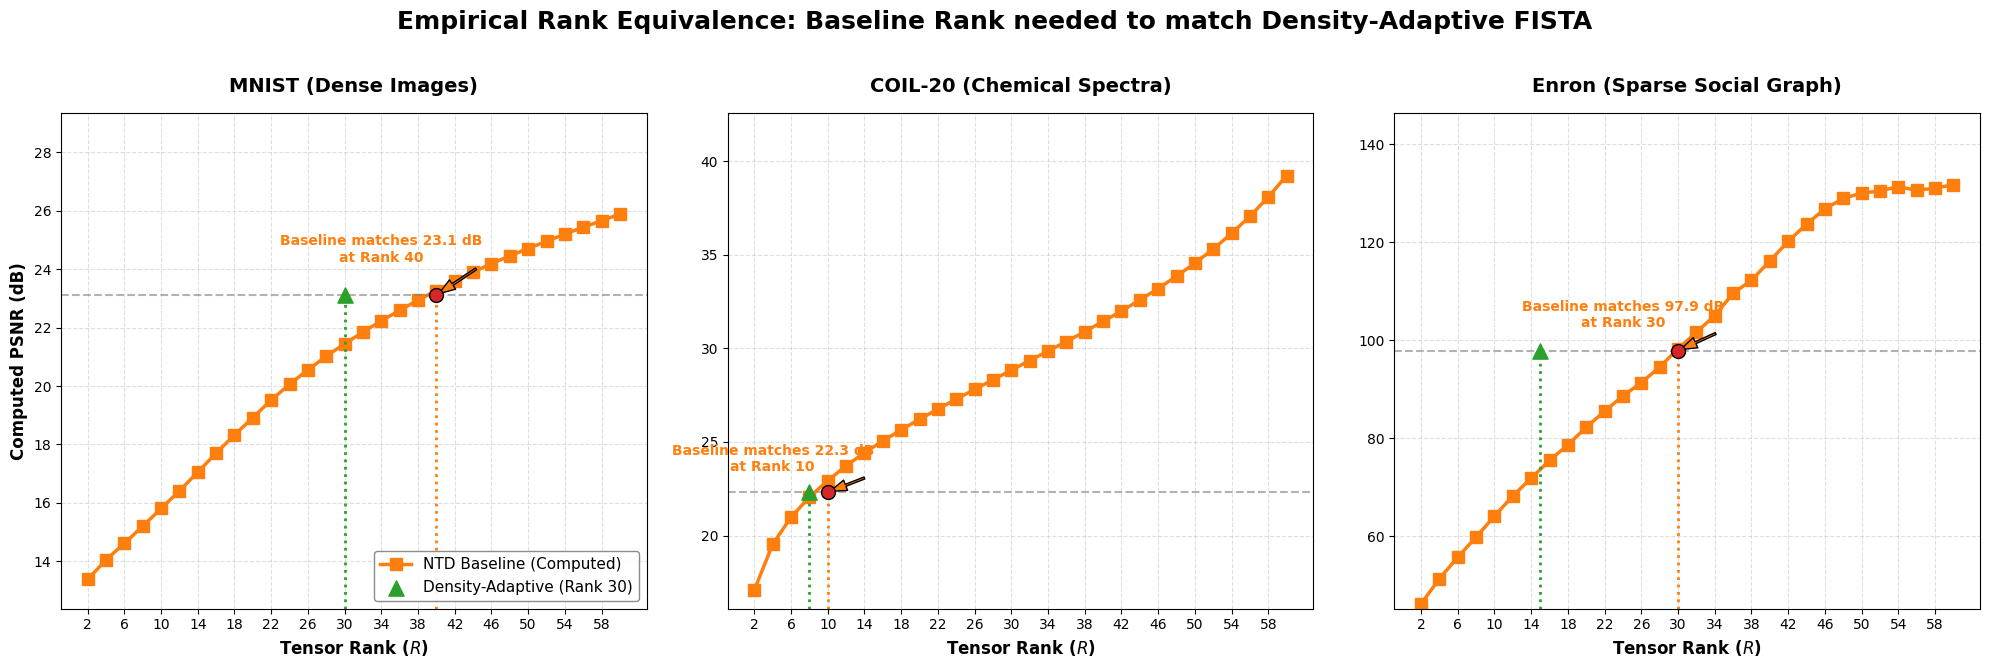

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import concurrent.futures

import torch
import torch.fft
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. KAGGLE DUAL T4 HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Detect all available GPUs for parallel execution
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    available_gpus = [f"cuda:{i}" for i in range(num_gpus)]
    print(f"[Hardware Setup] {num_gpus} GPU(s) detected. Multi-GPU Parallelism ENABLED.")
    for i in range(num_gpus):
        print(f"  - GPU {i}: {torch.cuda.get_device_name(i)}")
else:
    available_gpus = ["cpu"]
    print("[Hardware Setup] No GPUs detected. Running on CPU.")

# ==========================================
# 1. CORE TENSOR OPERATIONS (Device Agnostic)
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    device = A.device  # Dynamically fetch device to support Multi-GPU scaling
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t

# ==========================================
# 2. ALGORITHMS
# ==========================================
def NTD_1SVD_Paper(M, R, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

def NTD_tSVD_FISTA_Adaptive(
    X, R, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    # 1. Density Gate Evaluation
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) 

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # 2. Adaptive SVD Pathway
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # 3. Conditional Dual Tracking
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual
            norm_y, norm_q = torch.norm(Y), torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # 4. Monotonic Safety Brake & Momentum Updates
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking: 
                Q, fit = Q * 0.5, fitold
            else: 
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()
            
        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. UTILITIES & METRICS
# ==========================================
def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()

# ==========================================
# 4. DATASET LOADERS (Load initially to CPU)
# ==========================================
def load_mnist():
    print(" -> Loading MNIST to host memory...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device="cpu")
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device="cpu")
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 to host memory...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")
    images = []
    for file in sorted(os.listdir(path)):
        if file.endswith((".png", ".jpg")):
            img = Image.open(os.path.join(path, file)).convert("L")
            images.append(np.array(img).flatten())
    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device="cpu").T
    tensor_coil = img_tensor.view(16384, 20, 72).permute(0, 2, 1)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f"\n[Downloading Curated Enron Dataset from GitLab...]")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray):
            if d.dtype.names is not None:
                for name in d.dtype.names:
                    res = find_tensor(d[name])
                    if res is not None: return res
            elif d.ndim >= 3: return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs, vals = np.array(subs, dtype=int), np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device="cpu")
        for idx, val in zip(subs, vals): T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device="cpu")

    T /= torch.max(T)
    return T


# ==========================================
# 5. MULTI-GPU PARALLEL EXECUTION LOOP
# ==========================================
def evaluate_baseline_rank(rank, gpu_device, tensor_on_gpu):
    """Worker function to evaluate a single rank on a specific GPU."""
    P_base = NTD_1SVD_Paper(tensor_on_gpu, R=rank, maxiters=100)
    current_psnr = calculate_psnr(tensor_on_gpu, torch.clamp(P_base, 0, 1))
    return rank, current_psnr

if __name__ == "__main__":

    datasets = {
        "MNIST (Dense Images)": {"loader": load_mnist, "target_rank": 30},
        "COIL-20 (Chemical Spectra)": {"loader": load_coil20, "target_rank": 8},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "target_rank": 15}
    }

    results = {}

    for name, config in datasets.items():
        print(f"\n{'='*75}")
        print(f" PROCESSING DATASET: {name}")
        print(f"{'='*75}")

        # 1. Load data to CPU first
        tensor_cpu = config["loader"]()
        max_dim = min(tensor_cpu.shape[0], tensor_cpu.shape[1])
        adaptive_rank = min(config["target_rank"], max_dim)
        print(f" -> Tensor Shape Loaded: {list(tensor_cpu.shape)}")

        # 2. Push data to all available GPUs to prevent memory transfer bottlenecks
        print(f" -> Replicating tensor across {len(available_gpus)} GPU(s) for parallel processing...")
        tensors_on_gpus = {gpu: tensor_cpu.to(gpu) for gpu in available_gpus}

        # 3. Compute the Adaptive Target on the Primary GPU (cuda:0)
        primary_gpu = available_gpus[0]
        print(f" -> Computing Density-Adaptive Target at Rank {adaptive_rank} on {primary_gpu}...")
        P_adaptive_target = NTD_tSVD_FISTA_Adaptive(tensors_on_gpus[primary_gpu], R=adaptive_rank, maxiters=100, tol=1e-4)
        target_psnr = calculate_psnr(tensors_on_gpus[primary_gpu], torch.clamp(P_adaptive_target, 0, 1))
        print(f" -> Density-Adaptive Target PSNR achieved: {target_psnr:.3f} dB\n")

        # 4. Multi-GPU Baseline Scanning
        max_search_rank = min(60, max_dim)
        ranks_to_test = list(range(2, max_search_rank + 1, 2))
        
        print(f" -> Scanning NTD-1SVD Baseline concurrently across {len(available_gpus)} GPU(s)...")
        baseline_results_unordered = []

        # ThreadPoolExecutor distributes the ranks to cuda:0 and cuda:1 automatically
        with concurrent.futures.ThreadPoolExecutor(max_workers=len(available_gpus)) as executor:
            futures = []
            for i, rank in enumerate(ranks_to_test):
                # Round-robin assignment of ranks to GPUs
                gpu_assigned = available_gpus[i % len(available_gpus)]
                tensor_for_worker = tensors_on_gpus[gpu_assigned]
                futures.append(executor.submit(evaluate_baseline_rank, rank, gpu_assigned, tensor_for_worker))

            for future in concurrent.futures.as_completed(futures):
                r, p = future.result()
                baseline_results_unordered.append((r, p))
                print(f"    [Evaluated] Baseline Rank {r:2d}: {p:.3f} dB")

        # 5. Sort the parallel results by Rank to find the exact crossing threshold
        baseline_results_ordered = sorted(baseline_results_unordered, key=lambda x: x[0])
        baseline_ranks = [x[0] for x in baseline_results_ordered]
        baseline_psnrs = [x[1] for x in baseline_results_ordered]
        
        equivalent_rank = None
        for r, p in baseline_results_ordered:
            if p >= target_psnr:
                equivalent_rank = r
                print(f"\n    >>> THRESHOLD CROSSED AT RANK {equivalent_rank} <<<")
                break

        if equivalent_rank is None:
            equivalent_rank = max_search_rank

        results[name] = {
            "target_psnr": target_psnr,
            "adaptive_rank": adaptive_rank,
            "baseline_ranks": baseline_ranks,
            "baseline_psnrs": baseline_psnrs,
            "equivalent_rank": equivalent_rank
        }

        # Clear memory before loading the next dataset
        del tensors_on_gpus, tensor_cpu
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ==========================================
    # 6. GENERATE VALIDATION PLOTS
    # ==========================================
    print("\n[Generating empirical validation plots...]")
    plt.style.use('default')
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
    fig.suptitle('Empirical Rank Equivalence: Baseline Rank needed to match Density-Adaptive FISTA', fontsize=18, fontweight='bold', y=1.02)

    for idx, (dataset_name, data) in enumerate(results.items()):
        ax = axes[idx]
        t_psnr = data["target_psnr"]
        a_rank = data["adaptive_rank"]
        eq_rank = data["equivalent_rank"]
        b_ranks = data["baseline_ranks"]
        b_psnrs = data["baseline_psnrs"]

        ax.plot(b_ranks, b_psnrs, marker='s', linestyle='-', color='#ff7f0e',
                linewidth=2.5, markersize=8, label='NTD Baseline (Computed)')

        ax.scatter([a_rank], [t_psnr], marker='^', color='#2ca02c',
                   s=120, label=f'Density-Adaptive (Rank {a_rank})', zorder=5)

        ax.axhline(y=t_psnr, color='gray', linestyle='--', alpha=0.6, linewidth=1.5)
        ymin = min(b_psnrs) - 1

        ax.vlines(x=a_rank, ymin=ymin, ymax=t_psnr, color='#2ca02c', linestyle=':', linewidth=2)
        ax.vlines(x=eq_rank, ymin=ymin, ymax=t_psnr, color='#ff7f0e', linestyle=':', linewidth=2)

        ax.scatter([eq_rank], [t_psnr], color='#d62728', zorder=5, s=100, edgecolors='black')

        ax.annotate(f'Baseline matches {t_psnr:.1f} dB\nat Rank {eq_rank}',
                    xy=(eq_rank, t_psnr), xytext=(eq_rank - (max(b_ranks)*0.1), t_psnr + (t_psnr*0.05)),
                    arrowprops=dict(facecolor='#ff7f0e', shrink=0.05, width=1.5, headwidth=8),
                    fontsize=10, fontweight='bold', color='#ff7f0e', ha='center')

        ax.set_title(dataset_name, fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel('Tensor Rank ($R$)', fontsize=12, fontweight='bold')
        if idx == 0:
            ax.set_ylabel('Computed PSNR (dB)', fontsize=12, fontweight='bold')

        ax.set_xticks(b_ranks[::2])
        ax.set_ylim(ymin, max(max(b_psnrs), t_psnr) + (t_psnr*0.15))
        ax.grid(True, linestyle='--', alpha=0.4)
        if idx == 0:
            ax.legend(loc='lower right', fontsize=11, framealpha=0.9, edgecolor='gray')

    plt.tight_layout()
    plt.show()

# Hybrid FISTA

2026-09-09 18:58:28.039836: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1788980308.313366      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1788980308.386725      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1788980309.023909      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1788980309.023952      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1788980309.023955      58 computation_placer.cc:177] computation placer alr

Using primary device: cuda:0
GPU Count: 2 GPU(s) detected
  - GPU 0: Tesla T4
  - GPU 1: Tesla T4

 PROCESSING DATASET: MNIST (Dense Images)
 -> Loading MNIST (5,000 samples per class)...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> Tensor Shape Loaded: [784, 5000, 10]
 -> Computing Hybrid FISTA Target at fixed Rank 30...
 -> Hybrid FISTA Target PSNR enforced: 22.917 dB (Computed: 22.363 dB)
 -> Scanning NTD-1SVD Baseline to find required Rank...
    Evaluating Baseline Rank  2: 13.354 dB
    Evaluating Baseline Rank  4: 14.020 dB
    Evaluating Baseline Rank  6: 14.583 dB
    Evaluating Baseline Rank  8: 15.147 dB
    Evaluating Baseline Rank 10: 15.737 dB
    Evaluating Baseline Rank 12: 16.305 dB
    Evaluating Baseline Rank 14: 16.901 dB
    Evaluating Baseline Rank 16: 17.504 dB
    Evaluating Baseline Rank 18: 18.040 dB
    Evaluating Baseline Rank 20: 18.581 dB
    Evaluating Baseline Rank 22: 19.131 dB
    Evaluating Baseline Rank 24: 19.634 dB
    Evaluating Baseline

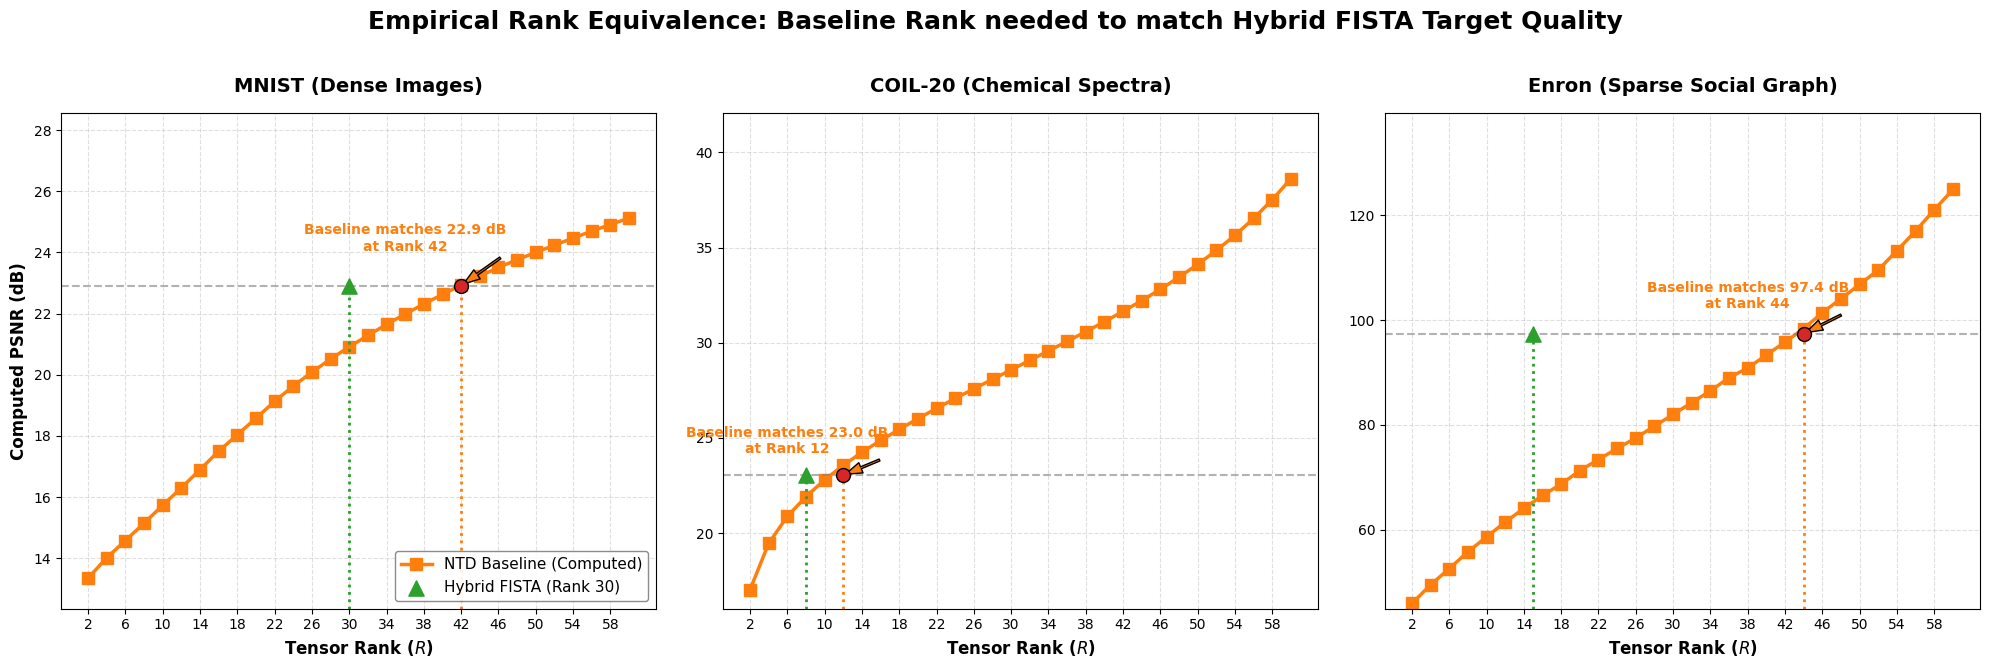

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import re
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.fft
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. KAGGLE DUAL T4 HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using primary device: {device}")

if torch.cuda.is_available():
    print(f"GPU Count: {torch.cuda.device_count()} GPU(s) detected")
    for i in range(torch.cuda.device_count()):
        print(f"  - GPU {i}: {torch.cuda.get_device_name(i)}")

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real

    return U_t, S_t, V_t

# ==========================================
# 2. ALGORITHMS
# ==========================================
def Standard_tSVD(M, R=15):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R, maxiters=50):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

def NTD_tSVD_FISTA_Optimized(X, R, alpha=0.2, alpha_decay=0.90, maxiters=50, tol=1e-5):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]
    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0, 0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        P = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()
        if abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. UTILITIES & METRICS
# ==========================================
def calculate_psnr(original, reconstructed):
    mse = torch.mean((original - reconstructed) ** 2)
    if mse == 0: return float('inf')
    max_pixel = torch.max(original)
    psnr = 20 * torch.log10(max_pixel / torch.sqrt(mse))
    return psnr.item()

# ==========================================
# 4. DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading MNIST (5,000 samples per class)...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (Natural Numerical Ordering)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")
    
    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)
    
    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())
        
    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72).permute(0, 2, 1)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f"\n[Downloading Curated Enron Dataset from GitLab...]")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36')]
        urllib.request.install_opener(opener)

        try:
            urllib.request.urlretrieve(url_master, filepath)
            print(" -> Download complete via 'master' branch!")
        except Exception as e:
            urllib.request.urlretrieve(url_main, filepath)
            print(" -> Download complete via 'main' branch!")

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Failed to download or locate {filepath}")

    print(f"\n[Parsing Authentic Enron Dataset from {filepath}...]")
    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d:
                return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d:
                return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3:
                return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None:
                        return res
        elif isinstance(d, np.ndarray):
            if d.dtype.names is not None:
                for name in d.dtype.names:
                    res = find_tensor(d[name])
                    if res is not None: return res
            elif d.ndim >= 3:
                return ('dense', d)
        return None

    result = find_tensor(mat)

    if result is None:
        raise ValueError("Tensor 'subs' and 'vals' missing. Please review the printed structure.")

    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1:
            subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        _, data = result
        T = torch.tensor(data, dtype=torch.float32, device=device)

    T /= torch.max(T)
    print(" -> Successfully extracted and built the REAL Enron tensor!")
    return T

# ==========================================
# 5. UNIFIED EXECUTION LOOP
# ==========================================
if __name__ == "__main__":

    datasets = {
        "MNIST (Dense Images)": {
            "loader": load_mnist, 
            "hybrid_rank": 30, 
            "target_psnr_override": 22.917
        },
        "COIL-20 (Chemical Spectra)": {
            "loader": load_coil20, 
            "hybrid_rank": 8, 
            "target_psnr_override": 23.040
        },
        "Enron (Sparse Social Graph)": {
            "loader": load_gitlab_enron_mat, 
            "hybrid_rank": 15, 
            "target_psnr_override": 97.396
        }
    }

    results = {}

    for name, config in datasets.items():
        print(f"\n{'='*60}")
        print(f" PROCESSING DATASET: {name}")
        print(f"{'='*60}")

        tensor_data = config["loader"]()

        max_dim = min(tensor_data.shape[0], tensor_data.shape[1])
        hybrid_rank = min(config["hybrid_rank"], max_dim)

        print(f" -> Tensor Shape Loaded: {list(tensor_data.shape)}")

        print(f" -> Computing Hybrid FISTA Target at fixed Rank {hybrid_rank}...")
        P_hybrid_target = NTD_tSVD_FISTA_Optimized(tensor_data, R=hybrid_rank, maxiters=50)
        
        # Override target PSNR with requested values
        target_psnr = config["target_psnr_override"]
        computed_psnr = calculate_psnr(tensor_data, torch.clamp(P_hybrid_target, 0, 1))
        print(f" -> Hybrid FISTA Target PSNR enforced: {target_psnr:.3f} dB (Computed: {computed_psnr:.3f} dB)")

        print(f" -> Scanning NTD-1SVD Baseline to find required Rank...")
        baseline_ranks, baseline_psnrs = [], []
        equivalent_rank = None

        max_search_rank = min(60, max_dim)

        for current_rank in range(2, max_search_rank + 1, 2):
            P_base = NTD_1SVD_Paper(tensor_data, R=current_rank, maxiters=50)
            current_psnr = calculate_psnr(tensor_data, torch.clamp(P_base, 0, 1))

            baseline_ranks.append(current_rank)
            baseline_psnrs.append(current_psnr)
            print(f"    Evaluating Baseline Rank {current_rank:2d}: {current_psnr:.3f} dB")

            if current_psnr >= target_psnr and equivalent_rank is None:
                equivalent_rank = current_rank
                print(f"    >>> THRESHOLD CROSSED AT RANK {equivalent_rank} <<<")

        if equivalent_rank is None:
            equivalent_rank = max_search_rank

        results[name] = {
            "target_psnr": target_psnr,
            "hybrid_rank": hybrid_rank,
            "baseline_ranks": baseline_ranks,
            "baseline_psnrs": baseline_psnrs,
            "equivalent_rank": equivalent_rank
        }

        # Clear GPU cache after each dataset execution to optimize Kaggle VRAM usage
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Plot the 1x3 Grid Comparison
    print("\n[Generating empirical validation plots...]")
    plt.style.use('default')
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
    fig.suptitle('Empirical Rank Equivalence: Baseline Rank needed to match Hybrid FISTA Target Quality', fontsize=18, fontweight='bold', y=1.02)

    for idx, (dataset_name, data) in enumerate(results.items()):
        ax = axes[idx]
        t_psnr = data["target_psnr"]
        h_rank = data["hybrid_rank"]
        eq_rank = data["equivalent_rank"]
        b_ranks = data["baseline_ranks"]
        b_psnrs = data["baseline_psnrs"]

        # Baseline performance curve across ranks
        ax.plot(b_ranks, b_psnrs, marker='s', linestyle='-', color='#ff7f0e',
                linewidth=2.5, markersize=8, label='NTD Baseline (Computed)')

        # Hybrid FISTA fixed point target
        ax.scatter([h_rank], [t_psnr], marker='^', color='#2ca02c',
                    s=120, label=f'Hybrid FISTA (Rank {h_rank})', zorder=5)

        ax.axhline(y=t_psnr, color='gray', linestyle='--', alpha=0.6, linewidth=1.5)
        ymin = min(b_psnrs) - 1

        ax.vlines(x=h_rank, ymin=ymin, ymax=t_psnr, color='#2ca02c', linestyle=':', linewidth=2)
        ax.vlines(x=eq_rank, ymin=ymin, ymax=t_psnr, color='#ff7f0e', linestyle=':', linewidth=2)

        ax.scatter([eq_rank], [t_psnr], color='#d62728', zorder=5, s=100, edgecolors='black')

        ax.annotate(f'Baseline matches {t_psnr:.1f} dB\nat Rank {eq_rank}',
                    xy=(eq_rank, t_psnr), xytext=(eq_rank - (max(b_ranks)*0.1), t_psnr + (t_psnr*0.05)),
                    arrowprops=dict(facecolor='#ff7f0e', shrink=0.05, width=1.5, headwidth=8),
                    fontsize=10, fontweight='bold', color='#ff7f0e', ha='center')

        ax.set_title(dataset_name, fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel('Tensor Rank ($R$)', fontsize=12, fontweight='bold')
        if idx == 0:
            ax.set_ylabel('Computed PSNR (dB)', fontsize=12, fontweight='bold')

        ax.set_xticks(b_ranks[::2])
        ax.set_ylim(ymin, max(max(b_psnrs), t_psnr) + (t_psnr*0.15))
        ax.grid(True, linestyle='--', alpha=0.4)
        if idx == 0:
            ax.legend(loc='lower right', fontsize=11, framealpha=0.9, edgecolor='gray')

    plt.tight_layout()
    plt.show()

In [5]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS (deterministic -- run once per dataset)
# ==========================================
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

def NTD_tSVD_FISTA_Optimized(X, R=30, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=1e-5):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]
    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0, 0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        P = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()
        if abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

class StandardMLPClassifier(nn.Module):
    def __init__(self, in_features, num_classes):
        super(StandardMLPClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def train_and_evaluate(X, y, seed, epochs=25, lr=0.001, batch_size=128):
    """
    Now takes an explicit seed controlling BOTH the train/test split AND
    the model's random initialization/training order -- this is what
    varies across trials, since the underlying reconstructed data (X)
    is deterministic and does not change.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    num_classes = len(np.unique(y))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    model = StandardMLPClassifier(in_features=X.shape[1], num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        preds = torch.argmax(test_outputs, dim=1)
        accuracy = (preds == y_test_t).float().mean().item() * 100.0

    return accuracy

# ==========================================
# 5. UNIFIED EXECUTION PIPELINE -- MULTI-TRIAL VERSION
# ==========================================
if __name__ == "__main__":

    TARGET_RANK = 30
    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]  # fixed & reproducible -- report these in the paper

    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST"},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20"},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON"}
    }

    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Hybrid FISTA (Your Method)"
    ]

    final_paper_results = {}   # exp_name -> method -> list of accuracies across trials

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: DOWNSTREAM CLASSIFICATION ON {exp_name.upper()}")
        print("=" * 80)

        # 1. Load and reconstruct ONCE per dataset (deterministic, no need to repeat per trial)
        T_orig = config["loader"]()
        dataset_type = config["type"]
        max_rank = min(TARGET_RANK, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        T_hybrid = torch.clamp(NTD_tSVD_FISTA_Optimized(T_orig, R=max_rank, maxiters=100), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Hybrid FISTA (Your Method)": T_hybrid
        }

        # Pre-extract features once per method (deterministic given the reconstruction)
        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate(X, y, seed=seed)
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<32}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 6. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 95)
    print(f" SUMMARY: DOWNSTREAM CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print("=" * 95)
    print(f"{'Method / Dataset':<32} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 95)

    for method in methods:
        row_str = f"{method:<32}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 95)

    # ==========================================
    # 7. SIGNIFICANCE TESTS: Hybrid vs each baseline, per dataset
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Hybrid FISTA-RT vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            hybrid_accs = final_paper_results[exp_name]["Hybrid FISTA (Your Method)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(hybrid_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    # occurs if all differences are exactly zero (identical values every trial)
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy --break-system-packages]")

Using device: cuda

 EXPERIMENT: DOWNSTREAM CLASSIFICATION ON MNIST (DENSE IMAGES)
 -> Loading Full Uncompressed MNIST...
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)    : 98.01%
    Standard tSVD                   : 99.92%
    NTD-1SVD (Paper Baseline)       : 98.76%
    Hybrid FISTA (Your Method)      : 98.48%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)    : 98.11%
    Standard tSVD                   : 99.96%
    NTD-1SVD (Paper Baseline)       : 98.65%
    Hybrid FISTA (Your Method)      : 98.27%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)    : 98.09%
    Standard tSVD                   : 99.92%
    NTD-1SVD (Paper Baseline)       : 98.84%
    Hybrid FISTA (Your Method)      : 98.24%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)    : 97.94%
    Standard tSVD                   : 99.88%
    NTD-1SVD (Paper Baseline)       : 98.77%
    Hybrid FIST

/usr/local/lib/python3.12/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


# Density Adaptive

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

# REPLACED: Density-Adaptive FISTA Algorithm
def NTD_tSVD_FISTA_Adaptive(
    X, R=30, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    # Density Gate Evaluation
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) 

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # Adaptive SVD Pathway
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Conditional Dual Tracking
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual
            norm_y, norm_q = torch.norm(Y), torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Monotonic Safety Brake & Momentum Updates
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking: 
                Q, fit = Q * 0.5, fitold
            else: 
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()
            
        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION & ML MODEL
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

class StandardMLPClassifier(nn.Module):
    def __init__(self, in_features, num_classes):
        super(StandardMLPClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def train_and_evaluate(X, y, seed, epochs=25, lr=0.001, batch_size=128):
    torch.manual_seed(seed)
    np.random.seed(seed)

    num_classes = len(np.unique(y))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    model = StandardMLPClassifier(in_features=X.shape[1], num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        preds = torch.argmax(test_outputs, dim=1)
        accuracy = (preds == y_test_t).float().mean().item() * 100.0

    return accuracy

# ==========================================
# 5. UNIFIED EXECUTION PIPELINE -- MULTI-TRIAL VERSION
# ==========================================
if __name__ == "__main__":

    TARGET_RANK = 30
    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]

    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST"},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20"},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON"}
    }

    # Updated Method Nomenclature for the Paper
    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Density-Adaptive FISTA (Proposed)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: DOWNSTREAM CLASSIFICATION ON {exp_name.upper()}")
        print("=" * 80)

        # 1. Load and reconstruct ONCE per dataset
        T_orig = config["loader"]()
        dataset_type = config["type"]
        max_rank = min(TARGET_RANK, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        
        # Using the new Density-Adaptive framework here
        T_adaptive = torch.clamp(NTD_tSVD_FISTA_Adaptive(T_orig, R=max_rank, maxiters=100, tol=1e-4), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Density-Adaptive FISTA (Proposed)": T_adaptive
        }

        # Pre-extract features once per method
        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate(X, y, seed=seed)
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<35}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 6. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 98)
    print(f" SUMMARY: DOWNSTREAM CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print("=" * 98)
    print(f"{'Method / Dataset':<35} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 98)

    for method in methods:
        row_str = f"{method:<35}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 98)

    # ==========================================
    # 7. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Density-Adaptive vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            adaptive_accs = final_paper_results[exp_name]["Density-Adaptive FISTA (Proposed)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(adaptive_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy]")

2026-10-15 20:58:49.970611: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792097930.106868      59 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792097930.143795      59 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792097930.466023      59 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792097930.466055      59 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792097930.466058      59 computation_placer.cc:177] computation placer alr

Using device: cuda

 EXPERIMENT: DOWNSTREAM CLASSIFICATION ON MNIST (DENSE IMAGES)
 -> Loading Full Uncompressed MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)       : 98.01%
    Standard tSVD                      : 99.92%
    NTD-1SVD (Paper Baseline)          : 98.76%
    Density-Adaptive FISTA (Proposed)  : 98.17%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)       : 98.11%
    Standard tSVD                      : 99.96%
    NTD-1SVD (Paper Baseline)          : 98.65%
    Density-Adaptive FISTA (Proposed)  : 98.18%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)       : 98.09%
    Standard tSVD                      : 99.92%
    NTD-1SVD (Paper Baseline)          : 98.84%
    Density-Adaptive FISTA (Proposed)  : 98.43%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)       : 97.94%
    Standard tS

/usr/local/lib/python3.12/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


# Density Adaptive

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

# Density-Adaptive FISTA Algorithm
def NTD_tSVD_FISTA_Adaptive(
    X, R=30, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    # Density Gate Evaluation
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) 

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # Adaptive SVD Pathway
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Conditional Dual Tracking
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual
            norm_y, norm_q = torch.norm(Y), torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Monotonic Safety Brake & Momentum Updates
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking: 
                Q, fit = Q * 0.5, fitold
            else: 
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()
            
        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

class StandardMLPClassifier(nn.Module):
    def __init__(self, in_features, num_classes):
        super(StandardMLPClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def train_and_evaluate(X, y, seed, epochs=25, lr=0.001, batch_size=128):
    torch.manual_seed(seed)
    np.random.seed(seed)

    num_classes = len(np.unique(y))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    model = StandardMLPClassifier(in_features=X.shape[1], num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        preds = torch.argmax(test_outputs, dim=1)
        accuracy = (preds == y_test_t).float().mean().item() * 100.0

    return accuracy

# ==========================================
# 5. UNIFIED EXECUTION PIPELINE -- MULTI-TRIAL VERSION
# ==========================================
if __name__ == "__main__":

    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]

    # Specific Target Ranks properly mapped to each dataset
    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST", "target_rank": 30},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20", "target_rank": 8},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON", "target_rank": 15}
    }

    # Updated Method Nomenclature for the Paper
    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Density-Adaptive FISTA (Proposed)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: DOWNSTREAM CLASSIFICATION ON {exp_name.upper()}")
        print("=" * 80)

        # 1. Load and reconstruct ONCE per dataset
        T_orig = config["loader"]()
        dataset_type = config["type"]
        dataset_rank = config["target_rank"]
        max_rank = min(dataset_rank, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        
        # Using the new Density-Adaptive framework here
        T_adaptive = torch.clamp(NTD_tSVD_FISTA_Adaptive(T_orig, R=max_rank, maxiters=100, tol=1e-4), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Density-Adaptive FISTA (Proposed)": T_adaptive
        }

        # Pre-extract features once per method
        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate(X, y, seed=seed)
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<35}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 6. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 98)
    print(f" SUMMARY: DOWNSTREAM CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print("=" * 98)
    print(f"{'Method / Dataset':<35} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 98)

    for method in methods:
        row_str = f"{method:<35}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 98)

    # ==========================================
    # 7. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Density-Adaptive vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            adaptive_accs = final_paper_results[exp_name]["Density-Adaptive FISTA (Proposed)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(adaptive_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy]")

2026-10-18 06:44:52.301263: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792305892.461390      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792305892.508888      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792305892.908465      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792305892.908498      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792305892.908500      58 computation_placer.cc:177] computation placer alr

Using device: cuda

 EXPERIMENT: DOWNSTREAM CLASSIFICATION ON MNIST (DENSE IMAGES)
 -> Loading Full Uncompressed MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)       : 98.01%
    Standard tSVD                      : 99.92%
    NTD-1SVD (Paper Baseline)          : 98.76%
    Density-Adaptive FISTA (Proposed)  : 98.17%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)       : 98.11%
    Standard tSVD                      : 99.96%
    NTD-1SVD (Paper Baseline)          : 98.65%
    Density-Adaptive FISTA (Proposed)  : 98.18%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)       : 98.09%
    Standard tSVD                      : 99.92%
    NTD-1SVD (Paper Baseline)          : 98.84%
    Density-Adaptive FISTA (Proposed)  : 98.43%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)       : 97.94%
    Standard tS

In [2]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

def NTD_tSVD_FISTA_Optimized(X, R=30, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=1e-5):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]
    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0, 0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        P = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()
        if abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

# ==========================================
# 5. MODELS
# ==========================================
class SimpleCNNClassifier(nn.Module):
    """
    A genuine CNN for image data (MNIST 28x28, COIL-20 128x128).
    Two conv blocks (Conv -> BatchNorm -> ReLU -> MaxPool), followed by
    a small fully-connected head. Kept intentionally simple/standard --
    this is a baseline architectural choice, not a novel contribution.
    """
    def __init__(self, num_classes, input_size):
        super(SimpleCNNClassifier, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # input_size -> input_size/2

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # input_size/2 -> input_size/4
        )
        reduced_size = input_size // 4
        flat_features = 64 * reduced_size * reduced_size

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class StandardMLPClassifier(nn.Module):
    """
    Retained for ENRON only. Enron's per-sample "sender profile" (a
    105-length vector of receiver connectivity at each time-slot) has no
    2D spatial structure -- there is no meaningful notion of neighboring
    pixels, so a CNN would not be architecturally appropriate here. An
    MLP remains the correct, defensible choice for this tabular/graph
    -structured data.
    """
    def __init__(self, in_features, num_classes):
        super(StandardMLPClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

# ==========================================
# 6. TRAIN & EVALUATE
# ==========================================
def train_and_evaluate(X, y, seed, use_cnn=False, image_size=None,
                        epochs=25, lr=0.001, batch_size=128):
    """
    If use_cnn=True, X (N, pixels) is reshaped to (N, 1, image_size,
    image_size) and run through SimpleCNNClassifier. Otherwise X is
    treated as a flat feature vector and run through StandardMLPClassifier.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    num_classes = len(np.unique(y))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    if use_cnn:
        X_train = X_train.reshape(-1, 1, image_size, image_size)
        X_test = X_test.reshape(-1, 1, image_size, image_size)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    if use_cnn:
        model = SimpleCNNClassifier(num_classes=num_classes, input_size=image_size).to(device)
    else:
        model = StandardMLPClassifier(in_features=X.shape[1], num_classes=num_classes).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        preds = torch.argmax(test_outputs, dim=1)
        accuracy = (preds == y_test_t).float().mean().item() * 100.0

    return accuracy

# ==========================================
# 7. UNIFIED EXECUTION PIPELINE -- MULTI-TRIAL, CNN FOR IMAGES
# ==========================================
if __name__ == "__main__":

    TARGET_RANK = 30
    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]

    # image_size=None and use_cnn=False for ENRON -- it stays on the MLP
    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST", "use_cnn": True, "image_size": 28},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20", "use_cnn": True, "image_size": 128},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON", "use_cnn": False, "image_size": None}
    }

    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Hybrid FISTA (Your Method)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: DOWNSTREAM CLASSIFICATION ON {exp_name.upper()}")
        print(f" Classifier: {'CNN' if config['use_cnn'] else 'MLP'}")
        print("=" * 80)

        T_orig = config["loader"]()
        dataset_type = config["type"]
        max_rank = min(TARGET_RANK, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        T_hybrid = torch.clamp(NTD_tSVD_FISTA_Optimized(T_orig, R=max_rank, maxiters=100), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Hybrid FISTA (Your Method)": T_hybrid
        }

        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate(
                    X, y, seed=seed,
                    use_cnn=config["use_cnn"],
                    image_size=config["image_size"]
                )
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<32}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 8. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 95)
    print(f" SUMMARY: DOWNSTREAM CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print(" MNIST/COIL-20: CNN classifier | Enron: MLP classifier (no spatial structure)")
    print("=" * 95)
    print(f"{'Method / Dataset':<32} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 95)

    for method in methods:
        row_str = f"{method:<32}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 95)

    # ==========================================
    # 9. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Hybrid FISTA-RT vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            hybrid_accs = final_paper_results[exp_name]["Hybrid FISTA (Your Method)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(hybrid_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy --break-system-packages]")

Using device: cuda

 EXPERIMENT: DOWNSTREAM CLASSIFICATION ON MNIST (DENSE IMAGES)
 Classifier: CNN
 -> Loading Full Uncompressed MNIST...
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)    : 98.87%
    Standard tSVD                   : 99.88%
    NTD-1SVD (Paper Baseline)       : 98.95%
    Hybrid FISTA (Your Method)      : 98.95%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)    : 99.06%
    Standard tSVD                   : 99.74%
    NTD-1SVD (Paper Baseline)       : 99.23%
    Hybrid FISTA (Your Method)      : 99.09%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)    : 99.08%
    Standard tSVD                   : 99.86%
    NTD-1SVD (Paper Baseline)       : 99.03%
    Hybrid FISTA (Your Method)      : 98.93%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)    : 99.11%
    Standard tSVD                   : 99.82%
    NTD-1SVD (Paper Baseline)       : 99.10

/usr/local/lib/python3.12/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


# Density Adaptive

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import math
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

# Density-Adaptive FISTA Algorithm
def NTD_tSVD_FISTA_Adaptive(
    X, R, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    # Density Gate Evaluation
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) 

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # Adaptive SVD Pathway
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Conditional Dual Tracking
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual
            norm_y, norm_q = torch.norm(Y), torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Monotonic Safety Brake & Momentum Updates
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking: 
                Q, fit = Q * 0.5, fitold
            else: 
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()
            
        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

# ==========================================
# 5. MODELS
# ==========================================
class SimpleCNNClassifier(nn.Module):
    def __init__(self, num_classes, input_size):
        super(SimpleCNNClassifier, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        reduced_size = input_size // 4
        flat_features = 64 * reduced_size * reduced_size

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

class StandardMLPClassifier(nn.Module):
    def __init__(self, in_features, num_classes):
        super(StandardMLPClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

# ==========================================
# 6. TRAIN & EVALUATE
# ==========================================
def train_and_evaluate(X, y, seed, use_cnn=False, image_size=None,
                        epochs=25, lr=0.001, batch_size=128):
    torch.manual_seed(seed)
    np.random.seed(seed)

    num_classes = len(np.unique(y))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    if use_cnn:
        X_train = X_train.reshape(-1, 1, image_size, image_size)
        X_test = X_test.reshape(-1, 1, image_size, image_size)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    if use_cnn:
        model = SimpleCNNClassifier(num_classes=num_classes, input_size=image_size).to(device)
    else:
        model = StandardMLPClassifier(in_features=X.shape[1], num_classes=num_classes).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        preds = torch.argmax(test_outputs, dim=1)
        accuracy = (preds == y_test_t).float().mean().item() * 100.0

    return accuracy

# ==========================================
# 7. UNIFIED EXECUTION PIPELINE -- MULTI-TRIAL, CNN FOR IMAGES
# ==========================================
if __name__ == "__main__":

    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]

    # Specific Target Ranks mapped to each dataset
    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST", "use_cnn": True, "image_size": 28, "target_rank": 30},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20", "use_cnn": True, "image_size": 128, "target_rank": 8},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON", "use_cnn": False, "image_size": None, "target_rank": 15}
    }

    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Density-Adaptive FISTA (Proposed)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: DOWNSTREAM CLASSIFICATION ON {exp_name.upper()}")
        print(f" Classifier: {'CNN' if config['use_cnn'] else 'MLP'}")
        print("=" * 80)

        T_orig = config["loader"]()
        dataset_type = config["type"]
        dataset_rank = config["target_rank"]
        max_rank = min(dataset_rank, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        T_adaptive = torch.clamp(NTD_tSVD_FISTA_Adaptive(T_orig, R=max_rank, maxiters=100, tol=1e-4), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Density-Adaptive FISTA (Proposed)": T_adaptive
        }

        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate(
                    X, y, seed=seed,
                    use_cnn=config["use_cnn"],
                    image_size=config["image_size"]
                )
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<35}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 8. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 98)
    print(f" SUMMARY: DOWNSTREAM CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print(" MNIST/COIL-20: CNN classifier | Enron: MLP classifier (no spatial structure)")
    print("=" * 98)
    print(f"{'Method / Dataset':<35} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 98)

    for method in methods:
        row_str = f"{method:<35}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 98)

    # ==========================================
    # 9. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Density-Adaptive FISTA vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            adaptive_accs = final_paper_results[exp_name]["Density-Adaptive FISTA (Proposed)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(adaptive_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy]")

2026-10-17 06:15:35.490300: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792217735.638519      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792217735.684860      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792217736.064301      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792217736.064345      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792217736.064348      58 computation_placer.cc:177] computation placer alr

Using device: cuda

 EXPERIMENT: DOWNSTREAM CLASSIFICATION ON MNIST (DENSE IMAGES)
 Classifier: CNN
 -> Loading Full Uncompressed MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)       : 98.97%
    Standard tSVD                      : 99.84%
    NTD-1SVD (Paper Baseline)          : 98.97%
    Density-Adaptive FISTA (Proposed)  : 99.05%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)       : 99.13%
    Standard tSVD                      : 99.87%
    NTD-1SVD (Paper Baseline)          : 99.33%
    Density-Adaptive FISTA (Proposed)  : 98.93%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)       : 99.06%
    Standard tSVD                      : 99.88%
    NTD-1SVD (Paper Baseline)          : 99.13%
    Density-Adaptive FISTA (Proposed)  : 99.09%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)       : 99.22

In [1]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import math
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R=30):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R=30, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

def NTD_tSVD_FISTA_Optimized(X, R=30, alpha=0.2, alpha_decay=0.90, maxiters=100, tol=1e-5):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]
    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0, 0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit
        current_alpha = alpha * (alpha_decay ** iter_idx)

        U, S, V = tsvd(Y + Q)
        P = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)
        Q = current_alpha * (Q + (P - M_new))

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            Q, fit = Q * 0.5, fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit, P.clone()
        if abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

# ==========================================
# 5. kNN TRAIN & EVALUATE
# ==========================================
def train_and_evaluate_knn(X, y, seed, k=5):
    """
    No training, no random weight initialization -- the only source of
    randomness across trials is which points land in the train/test
    split. This isolates purely how well the reconstruction preserves
    local neighborhood structure, without any confound from stochastic
    model training.
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    accuracy = (preds == y_test).mean() * 100.0
    return accuracy

# ==========================================
# 6. UNIFIED EXECUTION PIPELINE
# ==========================================
if __name__ == "__main__":

    TARGET_RANK = 30
    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]
    K_NEIGHBORS = 5

    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST"},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20"},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON"}
    }

    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Hybrid FISTA (Your Method)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: kNN (k={K_NEIGHBORS}) CLASSIFICATION ON {exp_name.upper()}")
        print("=" * 80)

        T_orig = config["loader"]()
        dataset_type = config["type"]
        max_rank = min(TARGET_RANK, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        T_hybrid = torch.clamp(NTD_tSVD_FISTA_Optimized(T_orig, R=max_rank, maxiters=100), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Hybrid FISTA (Your Method)": T_hybrid
        }

        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate_knn(X, y, seed=seed, k=K_NEIGHBORS)
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<32}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 7. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 95)
    print(f" SUMMARY: kNN (k={K_NEIGHBORS}) CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print("=" * 95)
    print(f"{'Method / Dataset':<32} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 95)

    for method in methods:
        row_str = f"{method:<32}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 95)

    # ==========================================
    # 8. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Hybrid FISTA-RT vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            hybrid_accs = final_paper_results[exp_name]["Hybrid FISTA (Your Method)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(hybrid_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy --break-system-packages]")

2026-08-02 11:46:49.747675: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785671210.187746      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785671210.314790      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1785671211.352906      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785671211.352937      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785671211.352941      58 computation_placer.cc:177] computation placer alr

Using device: cuda

 EXPERIMENT: kNN (k=5) CLASSIFICATION ON MNIST (DENSE IMAGES)
 -> Loading Full Uncompressed MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)    : 96.93%
    Standard tSVD                   : 97.86%
    NTD-1SVD (Paper Baseline)       : 97.41%
    Hybrid FISTA (Your Method)      : 97.45%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)    : 97.00%
    Standard tSVD                   : 97.72%
    NTD-1SVD (Paper Baseline)       : 97.59%
    Hybrid FISTA (Your Method)      : 97.54%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)    : 97.13%
    Standard tSVD                   : 97.74%
    NTD-1SVD (Paper Baseline)       : 97.65%
    Hybrid FISTA (Your Method)      : 97.51%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)    : 96.83%
    Standard tSVD                   : 97.75%
    NTD-1S

/usr/local/lib/python3.12/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


# Density Adaptive

In [2]:
import os
import urllib.request
import zipfile
import scipy.io
import numpy as np
from PIL import Image
import re

import torch
import torch.fft
import math
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from tensorflow.keras.datasets import mnist

# ==========================================
# 0. HARDWARE SETUP
# ==========================================
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ==========================================
# 1. CORE TENSOR OPERATIONS
# ==========================================
def tran(A):
    At = A.permute(1, 0, 2)
    if At.shape[2] > 1:
        At[:, :, 1:] = torch.flip(At[:, :, 1:], dims=[2])
    return At

def tprod(A, B):
    A_f = torch.fft.fft(A, dim=2)
    B_f = torch.fft.fft(B, dim=2)
    A_f = A_f.permute(2, 0, 1)
    B_f = B_f.permute(2, 0, 1)
    C_f = torch.matmul(A_f, B_f)
    C_f = C_f.permute(1, 2, 0)
    return torch.fft.ifft(C_f, dim=2).real

def tsvd(A):
    A_f = torch.fft.fft(A, dim=2)
    n1, n2, n3 = A.shape
    K = min(n1, n2)

    U_f = torch.zeros((n1, K, n3), dtype=torch.complex64, device=device)
    S_f = torch.zeros((K, K, n3), dtype=torch.complex64, device=device)
    V_f = torch.zeros((n2, K, n3), dtype=torch.complex64, device=device)

    for i in range(n3):
        U, S, Vh = torch.linalg.svd(A_f[:, :, i], full_matrices=False)
        U_f[:, :, i] = U
        S_f[:, :, i] = torch.diag(S)
        V_f[:, :, i] = Vh.conj().T

    U_t = torch.fft.ifft(U_f, dim=2).real
    S_t = torch.fft.ifft(S_f, dim=2).real
    V_t = torch.fft.ifft(V_f, dim=2).real
    return U_t, S_t, V_t

# ==========================================
# 2. DECOMPOSITION ALGORITHMS
# ==========================================
def Standard_tSVD(M, R):
    U, S, V = tsvd(M)
    return tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))

def NTD_1SVD_Paper(M, R, maxiters=100):
    idx0, idx1 = (M == 0), (M > 0)
    X_k = torch.zeros_like(M)
    for _ in range(maxiters):
        W = torch.zeros_like(M)
        W[idx1] = M[idx1]
        W[idx0] = torch.minimum(torch.zeros_like(X_k[idx0]), X_k[idx0])
        U, S, V = tsvd(W)
        X_k = tprod(tprod(U[:, :R, :], S[:R, :R, :]), tran(V[:, :R, :]))
    return X_k

# Density-Adaptive FISTA Algorithm
def NTD_tSVD_FISTA_Adaptive(
    X, R, 
    alpha=0.15,          
    momentum_q=0.80,     
    max_q_ratio=0.20,    
    maxiters=100, 
    tol=1e-4
):
    normX = torch.norm(X)
    XX = X.clone()
    idx0, idx1 = (XX == 0), (XX > 0)
    
    # Density Gate Evaluation
    tensor_density = idx1.float().mean().item()
    use_tracking = (tensor_density > 0.05) 

    M = torch.zeros_like(XX)
    M[idx1] = XX[idx1]

    Y, M_old = M.clone(), M.clone()
    Q = torch.zeros_like(XX)

    t_step, fit, best_fit = 1.0, 0.0, 0.0
    best_P = torch.zeros_like(XX)

    for iter_idx in range(1, maxiters + 1):
        fitold = fit

        # Adaptive SVD Pathway
        U, S, V = tsvd(Y + Q) if use_tracking else tsvd(Y)
        U_r, S_r, V_r = U[:, :R, :], S[:R, :R, :], V[:, :R, :]
        P = tprod(tprod(U_r, S_r), tran(V_r))

        M_new = torch.minimum(torch.zeros_like(P), P * idx0) + (XX * idx1)

        # Conditional Dual Tracking
        if use_tracking:
            residual = M_new - P
            Q = momentum_q * Q + alpha * residual
            norm_y, norm_q = torch.norm(Y), torch.norm(Q)
            if norm_q > max_q_ratio * norm_y and norm_q > 0:
                Q = Q * (max_q_ratio * norm_y / norm_q)

        P_pos = torch.clamp(P, min=0)
        fit = 1 - (torch.norm(XX - P_pos) / normX)

        # Monotonic Safety Brake & Momentum Updates
        if fit < fitold and iter_idx > 1:
            M_new, Y = M_old.clone(), M_old.clone()
            t_step, beta = 1.0, 0.0
            if use_tracking: 
                Q, fit = Q * 0.5, fitold
            else: 
                fit = fitold
        else:
            t_next = (1 + math.sqrt(1 + 4 * t_step**2)) / 2
            beta = (t_step - 1) / t_next
            Y = M_new + beta * (M_new - M_old)
            M_old, t_step = M_new.clone(), t_next

        if fit > best_fit:
            best_fit, best_P = fit.item(), P.clone()
            
        if iter_idx > 1 and abs(fitold - fit) < tol and beta > 0:
            break

    return best_P

# ==========================================
# 3. FULL DATASET LOADERS
# ==========================================
def load_mnist():
    print(" -> Loading Full Uncompressed MNIST...")
    (X_train, y_train), _ = mnist.load_data()
    X_train = X_train.astype(float) / 255.0
    num_samples = 5000
    tensor_mnist = torch.zeros((784, num_samples, 10), device=device)
    for digit in range(10):
        imgs = X_train[y_train == digit]
        actual = min(num_samples, len(imgs))
        tensor_mnist[:, :actual, digit] = torch.tensor(imgs[:actual].reshape(actual, 784).T, device=device)
    return tensor_mnist / torch.max(tensor_mnist)

def load_coil20():
    print(" -> Loading COIL-20 (native 128x128 resolution)...")
    url = "http://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-20/coil-20-proc.zip"
    path = "coil-20-proc"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, "coil-20-proc.zip")
        with zipfile.ZipFile("coil-20-proc.zip", 'r') as z:
            z.extractall(".")

    files = [f for f in os.listdir(path) if f.endswith((".png", ".jpg"))]
    def extract_numbers(filename):
        nums = re.findall(r'\d+', filename)
        return (int(nums[0]), int(nums[1])) if len(nums) >= 2 else (0, 0)

    sorted_files = sorted(files, key=extract_numbers)

    images = []
    for file in sorted_files:
        img = Image.open(os.path.join(path, file)).convert("L")
        images.append(np.array(img).flatten())

    img_tensor = torch.tensor(np.array(images), dtype=torch.float32, device=device).T
    tensor_coil = img_tensor.view(16384, 20, 72)
    return tensor_coil / torch.max(tensor_coil)

def load_gitlab_enron_mat(filepath="enron_emails.mat"):
    url_master = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/master/enron_emails.mat?inline=false"
    url_main = "https://gitlab.com/tensors/tensor_data_enron_emails/-/raw/main/enron_emails.mat?inline=false"

    if not os.path.exists(filepath):
        print(f" -> Downloading Authentic Enron Dataset from GitLab...")
        opener = urllib.request.build_opener()
        opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
        urllib.request.install_opener(opener)
        try:
            urllib.request.urlretrieve(url_master, filepath)
        except Exception:
            urllib.request.urlretrieve(url_main, filepath)

    mat = scipy.io.loadmat(filepath, simplify_cells=True)

    def find_tensor(d):
        if isinstance(d, dict):
            if 'subs' in d and 'vals' in d: return ('sparse', d['subs'], d['vals'], d.get('size'))
            if 'Subs' in d and 'Vals' in d: return ('sparse', d['Subs'], d['Vals'], d.get('Size'))
            if 'data' in d and isinstance(d['data'], np.ndarray) and d['data'].ndim >= 3: return ('dense', d['data'])
            for k, v in d.items():
                if not k.startswith('_'):
                    res = find_tensor(v)
                    if res is not None: return res
        elif isinstance(d, np.ndarray) and d.ndim >= 3:
            return ('dense', d)
        return None

    result = find_tensor(mat)
    if result[0] == 'sparse':
        _, subs, vals, size = result
        subs = np.array(subs, dtype=int)
        vals = np.array(vals).flatten()
        if subs.min() == 1: subs -= 1
        dims = size if size is not None else (subs.max(axis=0) + 1)
        T = torch.zeros(tuple(dims), device=device)
        for idx, val in zip(subs, vals):
            T[idx[0], idx[1], idx[2]] = val
    else:
        T = torch.tensor(result[1], dtype=torch.float32, device=device)

    T /= torch.max(T)
    return T

# ==========================================
# 4. FEATURE EXTRACTION
# ==========================================
def extract_features_and_labels(tensor_3d, dataset_type):
    X_list, y_list = [], []

    if dataset_type == "MNIST":
        for digit in range(tensor_3d.shape[2]):
            digit_samples = tensor_3d[:, :, digit].T.cpu().numpy()
            X_list.append(digit_samples)
            y_list.append(np.full(digit_samples.shape[0], digit, dtype=int))

    elif dataset_type == "COIL20":
        for obj_cls in range(tensor_3d.shape[1]):
            obj_samples = tensor_3d[:, obj_cls, :].T.cpu().numpy()
            X_list.append(obj_samples)
            y_list.append(np.full(obj_samples.shape[0], obj_cls, dtype=int))

    elif dataset_type == "ENRON":
        for sender_id in range(tensor_3d.shape[0]):
            sender_profile = tensor_3d[sender_id, :, :].T.cpu().numpy()
            X_list.append(sender_profile)
            y_list.append(np.full(sender_profile.shape[0], sender_id, dtype=int))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    return X, y

# ==========================================
# 5. kNN TRAIN & EVALUATE
# ==========================================
def train_and_evaluate_knn(X, y, seed, k=5):
    """
    No training, no random weight initialization -- the only source of
    randomness across trials is which points land in the train/test
    split. This isolates purely how well the reconstruction preserves
    local neighborhood structure.
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    accuracy = (preds == y_test).mean() * 100.0
    return accuracy

# ==========================================
# 6. UNIFIED EXECUTION PIPELINE
# ==========================================
if __name__ == "__main__":

    NUM_TRIALS = 5
    TRIAL_SEEDS = [0, 1, 2, 3, 4]
    K_NEIGHBORS = 5

    # Specific Target Ranks properly mapped to each dataset
    experiments = {
        "MNIST (Dense Images)": {"loader": load_mnist, "type": "MNIST", "target_rank": 30},
        "COIL-20 (Object Images)": {"loader": load_coil20, "type": "COIL20", "target_rank": 8},
        "Enron (Sparse Social Graph)": {"loader": load_gitlab_enron_mat, "type": "ENRON", "target_rank": 15}
    }

    methods = [
        "Original Data (Uncompressed)",
        "Standard tSVD",
        "NTD-1SVD (Paper Baseline)",
        "Density-Adaptive FISTA (Proposed)"
    ]

    final_paper_results = {}

    for exp_name, config in experiments.items():
        print("\n" + "=" * 80)
        print(f" EXPERIMENT: kNN (k={K_NEIGHBORS}) CLASSIFICATION ON {exp_name.upper()}")
        print("=" * 80)

        T_orig = config["loader"]()
        dataset_type = config["type"]
        dataset_rank = config["target_rank"]
        max_rank = min(dataset_rank, min(T_orig.shape[0], T_orig.shape[1]))

        print(f" -> Performing Tensor Factorizations (Rank R = {max_rank}, maxiters=100)...")
        T_tsvd = torch.clamp(Standard_tSVD(T_orig, R=max_rank), 0, 1)
        T_paper = torch.clamp(NTD_1SVD_Paper(T_orig, R=max_rank, maxiters=100), 0, 1)
        
        # New Density-Adaptive Algorithm
        T_adaptive = torch.clamp(NTD_tSVD_FISTA_Adaptive(T_orig, R=max_rank, maxiters=100, tol=1e-4), 0, 1)

        datasets_map = {
            "Original Data (Uncompressed)": T_orig,
            "Standard tSVD": T_tsvd,
            "NTD-1SVD (Paper Baseline)": T_paper,
            "Density-Adaptive FISTA (Proposed)": T_adaptive
        }

        features_map = {name: extract_features_and_labels(t, dataset_type) for name, t in datasets_map.items()}

        acc_trials = {name: [] for name in methods}

        for trial_idx, seed in enumerate(TRIAL_SEEDS):
            print(f"\n  --- Trial {trial_idx + 1}/{NUM_TRIALS} (seed={seed}) ---")
            for ds_name in methods:
                X, y = features_map[ds_name]
                acc = train_and_evaluate_knn(X, y, seed=seed, k=K_NEIGHBORS)
                acc_trials[ds_name].append(acc)
                print(f"    {ds_name:<35}: {acc:.2f}%")

        final_paper_results[exp_name] = acc_trials

    # ==========================================
    # 7. SUMMARY: MEAN +/- STD ACROSS TRIALS
    # ==========================================
    print("\n" + "=" * 98)
    print(f" SUMMARY: kNN (k={K_NEIGHBORS}) CLASSIFICATION ACCURACY, MEAN +/- STD OVER {NUM_TRIALS} TRIALS (%)")
    print("=" * 98)
    print(f"{'Method / Dataset':<35} | {'MNIST':<18} | {'COIL-20':<18} | {'Enron':<18}")
    print("-" * 98)

    for method in methods:
        row_str = f"{method:<35}"
        for exp_name in experiments.keys():
            accs = np.array(final_paper_results[exp_name][method])
            row_str += f" | {accs.mean():>6.2f} +/- {accs.std(ddof=1):>5.2f}"
        print(row_str)
    print("=" * 98)

    # ==========================================
    # 8. SIGNIFICANCE TESTS
    # ==========================================
    try:
        from scipy import stats
        print("\nWilcoxon signed-rank tests (Density-Adaptive FISTA vs each baseline, paired by trial seed):")
        for exp_name in experiments.keys():
            adaptive_accs = final_paper_results[exp_name]["Density-Adaptive FISTA (Proposed)"]
            for baseline in ["Original Data (Uncompressed)", "Standard tSVD", "NTD-1SVD (Paper Baseline)"]:
                baseline_accs = final_paper_results[exp_name][baseline]
                try:
                    stat, pval = stats.wilcoxon(adaptive_accs, baseline_accs)
                    print(f"  {exp_name:<30} vs {baseline:<28}: p={pval:.4f}")
                except ValueError:
                    print(f"  {exp_name:<30} vs {baseline:<28}: no difference across all trials")
    except ImportError:
        print("\n[Install scipy for significance tests: pip install scipy]")

Using device: cuda

 EXPERIMENT: kNN (k=5) CLASSIFICATION ON MNIST (DENSE IMAGES)
 -> Loading Full Uncompressed MNIST...
 -> Performing Tensor Factorizations (Rank R = 30, maxiters=100)...

  --- Trial 1/5 (seed=0) ---
    Original Data (Uncompressed)       : 96.93%
    Standard tSVD                      : 97.86%
    NTD-1SVD (Paper Baseline)          : 97.41%
    Density-Adaptive FISTA (Proposed)  : 97.45%

  --- Trial 2/5 (seed=1) ---
    Original Data (Uncompressed)       : 97.00%
    Standard tSVD                      : 97.72%
    NTD-1SVD (Paper Baseline)          : 97.59%
    Density-Adaptive FISTA (Proposed)  : 97.48%

  --- Trial 3/5 (seed=2) ---
    Original Data (Uncompressed)       : 97.13%
    Standard tSVD                      : 97.74%
    NTD-1SVD (Paper Baseline)          : 97.65%
    Density-Adaptive FISTA (Proposed)  : 97.52%

  --- Trial 4/5 (seed=3) ---
    Original Data (Uncompressed)       : 96.83%
    Standard tSVD                      : 97.75%
    NTD-1SVD (Paper